# AffectFusion — Day 4 Proposal-Aligned Pipeline (v2): EDA Charts & 3-Model Baseline Suite

**Project:** *AffectFusion: A Cross-Attention Transformer Framework for Explainable Multimodal Emotion Recognition from Text and Emoji Semantics*  
**Inputs (from Day 3 Drive Output):** `/content/drive/MyDrive/AffectFusion_Day3/04_feature_engineered_final/` (`train_24k.csv`, `val_3k.csv`, `test_3k.csv`, `label_map.json`)  
**Output Workspace (Checkpointed After Every Stage):** `/content/drive/MyDrive/AffectFusion_Day4/`  
**Recommended Runtime:** **Colab Free Tier T4 GPU** (`Runtime → Change runtime type → T4 GPU` — full 3-model suite + all 10 charts finishes in **~30 minutes** using **≤ 4.3 GB peak VRAM** & **< 3 GB System RAM**!)

---

### 100% Alignment With Your Approved Title Proposal & Base Paper (Kusal et al., 2025)
1. **Stage 1 (Member 1 — Clean White-Background EDA Defense Charts, 300 DPI):**
   - `01_class_distribution_before_vs_after.png` — Day 2 Imbalanced Pool vs. Pre-Aug Real Train vs. Balanced 24K Train.
   - `02_language_distribution_per_class.png` — `ENG` / `BN` / `BNG` balance per class vs. 40/30/30 target.
   - `03_emoji_vs_non_emoji_per_class.png` — Emoji vs. Non-Emoji modality ratio per class vs. 70/30 reference.
   - `04_train_val_test_split_breakdown.png` — 80/10/10 split provenance highlighting your **5,000 Human-Verified Gold Rows** (`3,000` Test + `2,000` Val).
   - `05_gold_5k_cohens_kappa_heatmap.png` — Bonus 9×9 Human-vs-AI verification heatmap ($\kappa = 0.8087$).
2. **Stage 2 — Baseline A: `CNN-BiLSTM` Early Fusion (Adapted from Kusal et al., 2025 [1]):**
   - Replicates Kusal et al.'s exact early-fusion architecture: `128`-d text embeddings + `300`-d emoji embeddings concatenated into `428`-d fused vectors → `Conv1D(128 filters, kernel=5, ReLU)` → `MaxPool1D(2)` → `Bi-LSTM(64 units/dir = 128-d)` → `Dropout` → `Dense(64, ReLU)` → `9-class Softmax` (upgraded from English-only NNLM to multilingual subword embeddings so `ENG`, `BN`, and `BNG` are handled natively). Runs in **~2–3 minutes**.
3. **Stage 3 — Baseline B: `xlm-roberta-base` (Text-Only Unimodal Baseline):**
   - Fine-tuned strictly on `text_stream` (no emojis/demoji) under identical hyperparameters (`max_length=128`, `batch_size=16 × grad_accum=2 = 32`, `lr=2e-5`, `epochs=3`, `fp16=True`). Directly fulfills your proposal's **Text-Only baseline** requirement. Runs in **~12 minutes**.
4. **Stage 4 — Baseline C: `xlm-roberta-base` (Early Fusion: `Text + [SEP] + Demoji`):**
   - Encodes `(text_stream, demoji_text)` as a native XLM-R pair (`truncation="longest_first"`, `max_length=128`) under identical hyperparameters to Baseline B. Auto-reuses your existing `best_xlmr_baseline/` folder if already trained! Runs in **~13 minutes**.
5. **Stage 5 — Unified Evaluation, Statistical Significance Tests & Defense Visuals:**
   - Evaluates all 3 baselines on **`val_3k.csv`** and **100% Gold `test_3k.csv`**: **Accuracy**, **Macro-F1**, **Micro-F1**, **Weighted-F1**, **Per-Class P/R/F1**, **Per-Language (`ENG/BN/BNG`)**, and **Emoji vs. Non-Emoji** breakdowns.
   - Runs **Paired t-tests** (per your proposal Section 6), **McNemar's test**, and **1,000-sample paired bootstrap 95% CIs** comparing Early Fusion vs. Text-Only and XLM-R vs. CNN-BiLSTM.
   - Exports 5 white-background 300-DPI evaluation charts + `baseline_comparison_summary.csv` + `test_3k_error_analysis.csv`.


## Stage 0: Mount Google Drive, Colab-Safe Dependencies & Configuration
Run all 3 cells in Stage 0 at the start of **every** Colab session.


In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

# Read-only Day 2 & Day 3 inputs; Day 4 output workspace on Google Drive
DAY2_DIR = '/content/drive/MyDrive/AffectFusion_Day2_Gemini'
DAY3_DIR = '/content/drive/MyDrive/AffectFusion_Day3'
DAY4_DIR = '/content/drive/MyDrive/AffectFusion_Day4'

DIRS = {
    'day2_logs':         os.path.join(DAY2_DIR, 'logs'),
    'day3_final':        os.path.join(DAY3_DIR, '04_feature_engineered_final'),
    'day3_gold':         os.path.join(DAY3_DIR, '02_gold_verification'),
    'day3_logs':         os.path.join(DAY3_DIR, 'logs'),
    'base':              DAY4_DIR,
    'eda_charts':        os.path.join(DAY4_DIR, '01_eda_charts'),
    'model_ckpt':        os.path.join(DAY4_DIR, '02_xlmr_checkpoints'),
    'ckpt_cnn_bilstm':   os.path.join(DAY4_DIR, '02_xlmr_checkpoints', 'best_cnn_bilstm_kusal'),
    'ckpt_xlmr_text':    os.path.join(DAY4_DIR, '02_xlmr_checkpoints', 'best_xlmr_text_only'),
    'ckpt_xlmr_fusion':  os.path.join(DAY4_DIR, '02_xlmr_checkpoints', 'best_xlmr_baseline'),
    'eval_results':      os.path.join(DAY4_DIR, '03_evaluation_and_charts'),
    'logs':              os.path.join(DAY4_DIR, 'logs'),
}

for k, d in DIRS.items():
    if not k.startswith(('day2_', 'day3_')):
        os.makedirs(d, exist_ok=True)

TRAIN_CSV = os.path.join(DIRS['day3_final'], 'train_24k.csv')
VAL_CSV   = os.path.join(DIRS['day3_final'], 'val_3k.csv')
TEST_CSV  = os.path.join(DIRS['day3_final'], 'test_3k.csv')
TRAIN_PQ  = os.path.join(DIRS['day3_final'], 'train_24k.parquet')
VAL_PQ    = os.path.join(DIRS['day3_final'], 'val_3k.parquet')
TEST_PQ   = os.path.join(DIRS['day3_final'], 'test_3k.parquet')
LABEL_JS  = os.path.join(DIRS['day3_final'], 'label_map.json')

assert os.path.exists(TRAIN_CSV) and os.path.exists(VAL_CSV) and os.path.exists(TEST_CSV), (
    f"Day 3 train/val/test CSVs not found in {DIRS['day3_final']}!"
)

print("Google Drive mounted & Day 3 outputs verified:")
print("  train_24k.csv:", os.path.exists(TRAIN_CSV), "| parquet:", os.path.exists(TRAIN_PQ))
print("  val_3k.csv   :", os.path.exists(VAL_CSV),   "| parquet:", os.path.exists(VAL_PQ))
print("  test_3k.csv  :", os.path.exists(TEST_CSV),  "| parquet:", os.path.exists(TEST_PQ))
print("  Day 4 Output :", DAY4_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted & Day 3 outputs verified:
  train_24k.csv: True | parquet: True
  val_3k.csv   : True | parquet: True
  test_3k.csv  : True | parquet: True
  Day 4 Output : /content/drive/MyDrive/AffectFusion_Day4


In [2]:
# Colab-safe installs (no -U -> never breaks Colab's pre-installed torch/pandas/numpy)
!pip install -q transformers sentencepiece scikit-learn scipy seaborn matplotlib


In [3]:
import gc
import json
import time
import math
import random
from datetime import datetime, timezone
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from scipy import stats
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
from tqdm.auto import tqdm

# ==============================================================================
# DAY 4 MASTER CONFIGURATION (3 PROPOSAL-ALIGNED BASELINES)
# ==============================================================================
with open(LABEL_JS, "r", encoding="utf-8") as f:
    LABEL_META = json.load(f)

LABEL2ID    = LABEL_META["label2id"]
ID2LABEL    = {int(k): v for k, v in LABEL_META["id2label"].items()}
CLASSES     = [ID2LABEL[i] for i in range(len(ID2LABEL))]
NUM_CLASSES = len(CLASSES)

CONFIG = {
    "RANDOM_SEED": 42,
    "MODEL_NAME": "xlm-roberta-base",
    "MAX_LENGTH": 128,

    # Baseline A: Kusal et al. (2025) CNN-BiLSTM Early Fusion hyperparameters
    "CNN_TEXT_EMB_DIM": 128,            # Matches Kusal et al. NNLM d=128
    "CNN_EMOJI_EMB_DIM": 300,           # Matches Kusal et al. Emoji2Vec n=300
    "CNN_FILTERS": 128,                 # Matches Kusal et al. Table 3
    "CNN_KERNEL_SIZE": 5,               # Matches Kusal et al. Table 3
    "CNN_POOL_SIZE": 2,                 # Matches Kusal et al. Table 3
    "LSTM_HIDDEN": 64,                  # Matches Kusal et al. Table 3 (Bi-LSTM -> 128-d)
    "CNN_DROPOUT": 0.35,
    "CNN_BATCH_SIZE": 64,
    "CNN_LR": 1e-3,                     # Matches Kusal et al. Table 3
    "CNN_EPOCHS": 15,                   # Early stopping on Val Macro-F1 (patience=4)
    "CNN_PATIENCE": 4,
    "CNN_MIN_TOK_FREQ": 2,

    # Baselines B & C: xlm-roberta-base (Text-Only & Early Fusion) hyperparameters
    "XLMR_TRAIN_BATCH_SIZE": 16,        # Safe for Free T4 VRAM (~4.2 GB peak)
    "XLMR_EVAL_BATCH_SIZE": 32,
    "XLMR_GRAD_ACCUM_STEPS": 2,         # Effective batch size = 32
    "XLMR_LR": 2e-5,
    "XLMR_WEIGHT_DECAY": 0.01,
    "XLMR_EPOCHS": 3,
    "XLMR_WARMUP_RATIO": 0.10,
    "XLMR_MAX_GRAD_NORM": 1.0,
    "XLMR_LABEL_SMOOTHING": 0.05,
    "USE_FP16": True,
    "NUM_WORKERS": 2,

    # Saved logs & outputs on Google Drive
    "EDA_SUMMARY_JSON":         os.path.join(DIRS['logs'],         "stage1_eda_stats.json"),
    "HIST_CNN_JSON":            os.path.join(DIRS['logs'],         "stage2_cnn_bilstm_history.json"),
    "HIST_XLMR_TEXT_JSON":      os.path.join(DIRS['logs'],         "stage3_xlmr_text_only_history.json"),
    "HIST_XLMR_FUSION_JSON":    os.path.join(DIRS['logs'],         "stage4_xlmr_early_fusion_history.json"),
    "STATE_XLMR_TEXT_PT":       os.path.join(DIRS['model_ckpt'],   "resume_xlmr_text_only.pt"),
    "STATE_XLMR_FUSION_PT":     os.path.join(DIRS['model_ckpt'],   "resume_xlmr_early_fusion.pt"),
    "COMPARE_TABLE_CSV":        os.path.join(DIRS['eval_results'], "baseline_comparison_summary.csv"),
    "SIG_TESTS_JSON":           os.path.join(DIRS['logs'],         "stage5_statistical_significance_tests.json"),
    "EVAL_ALL_JSON":            os.path.join(DIRS['logs'],         "stage5_all_baselines_evaluation_report.json"),
    "TEST_ERRORS_CSV":          os.path.join(DIRS['eval_results'], "test_3k_error_analysis.csv"),
}

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(CONFIG["RANDOM_SEED"])

# Clean white-background global Matplotlib style (300 DPI defense slides)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.9,
    "axes.grid": True,
    "grid.color": "#E6E9EF",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": True,
    "legend.facecolor": "white",
    "legend.edgecolor": "#D0D7DE",
})

def load_split_compact(pq_path: str, csv_path: str, extra_cols: list = None) -> pd.DataFrame:
    base_cols = [
        "row_id", "text_stream", "emoji_stream", "demoji_text",
        "label", "label_id", "language_tag", "has_emoji",
        "emoji_count", "emoji_density", "text_length", "word_count",
        "is_augmented", "is_external_train_only",
    ]
    if extra_cols:
        base_cols = base_cols + [c for c in extra_cols if c not in base_cols]
    df = pd.read_parquet(pq_path) if os.path.exists(pq_path) else pd.read_csv(csv_path)
    keep = [c for c in base_cols if c in df.columns]
    if "is_human_verified" in df.columns and "is_human_verified" not in keep:
        keep.append("is_human_verified")
    return df[keep].copy()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hw = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (Switch to T4 GPU before Stage 2!)"
print("Day 4 v2 Master Configuration Ready:")
print("  Classes  :", CLASSES)
print("  Baselines: [A] CNN-BiLSTM Early Fusion (Kusal et al.) | [B] XLM-R Text-Only | [C] XLM-R Early Fusion")
print("  Hardware :", hw)


Day 4 v2 Master Configuration Ready:
  Classes  : ['Joy', 'Neutral', 'Anger', 'Sadness', 'Surprise', 'Sarcasm', 'Fear', 'Disgust', 'Anticipation']
  Baselines: [A] CNN-BiLSTM Early Fusion (Kusal et al.) | [B] XLM-R Text-Only | [C] XLM-R Early Fusion
  Hardware : Tesla T4


## Stage 1 (Member 1): Publication-Ready EDA Charts (White Background, 300 DPI)

Generates and saves all 4 required defense charts (+ 1 bonus 5,000-row Gold Human-vs-AI Kappa heatmap) directly to `/content/drive/MyDrive/AffectFusion_Day4/01_eda_charts/`:
1. `01_class_distribution_before_vs_after.png` — Imbalanced Day-2 Pool vs. Pre-Aug Real Train vs. Balanced 24K Train.
2. `02_language_distribution_per_class.png` — `ENG` / `BN` / `BNG` breakdown per class vs. 40/30/30 target.
3. `03_emoji_vs_non_emoji_per_class.png` — Emoji vs. Non-Emoji share per class vs. 70/30 reference.
4. `04_train_val_test_split_breakdown.png` — 80/10/10 split provenance (highlighting your 5,000 Gold rows) + per-class breakdown.
5. `05_gold_5k_cohens_kappa_heatmap.png` — 5,000-row Human-vs-AI verification heatmap ($\kappa = 0.8087$).


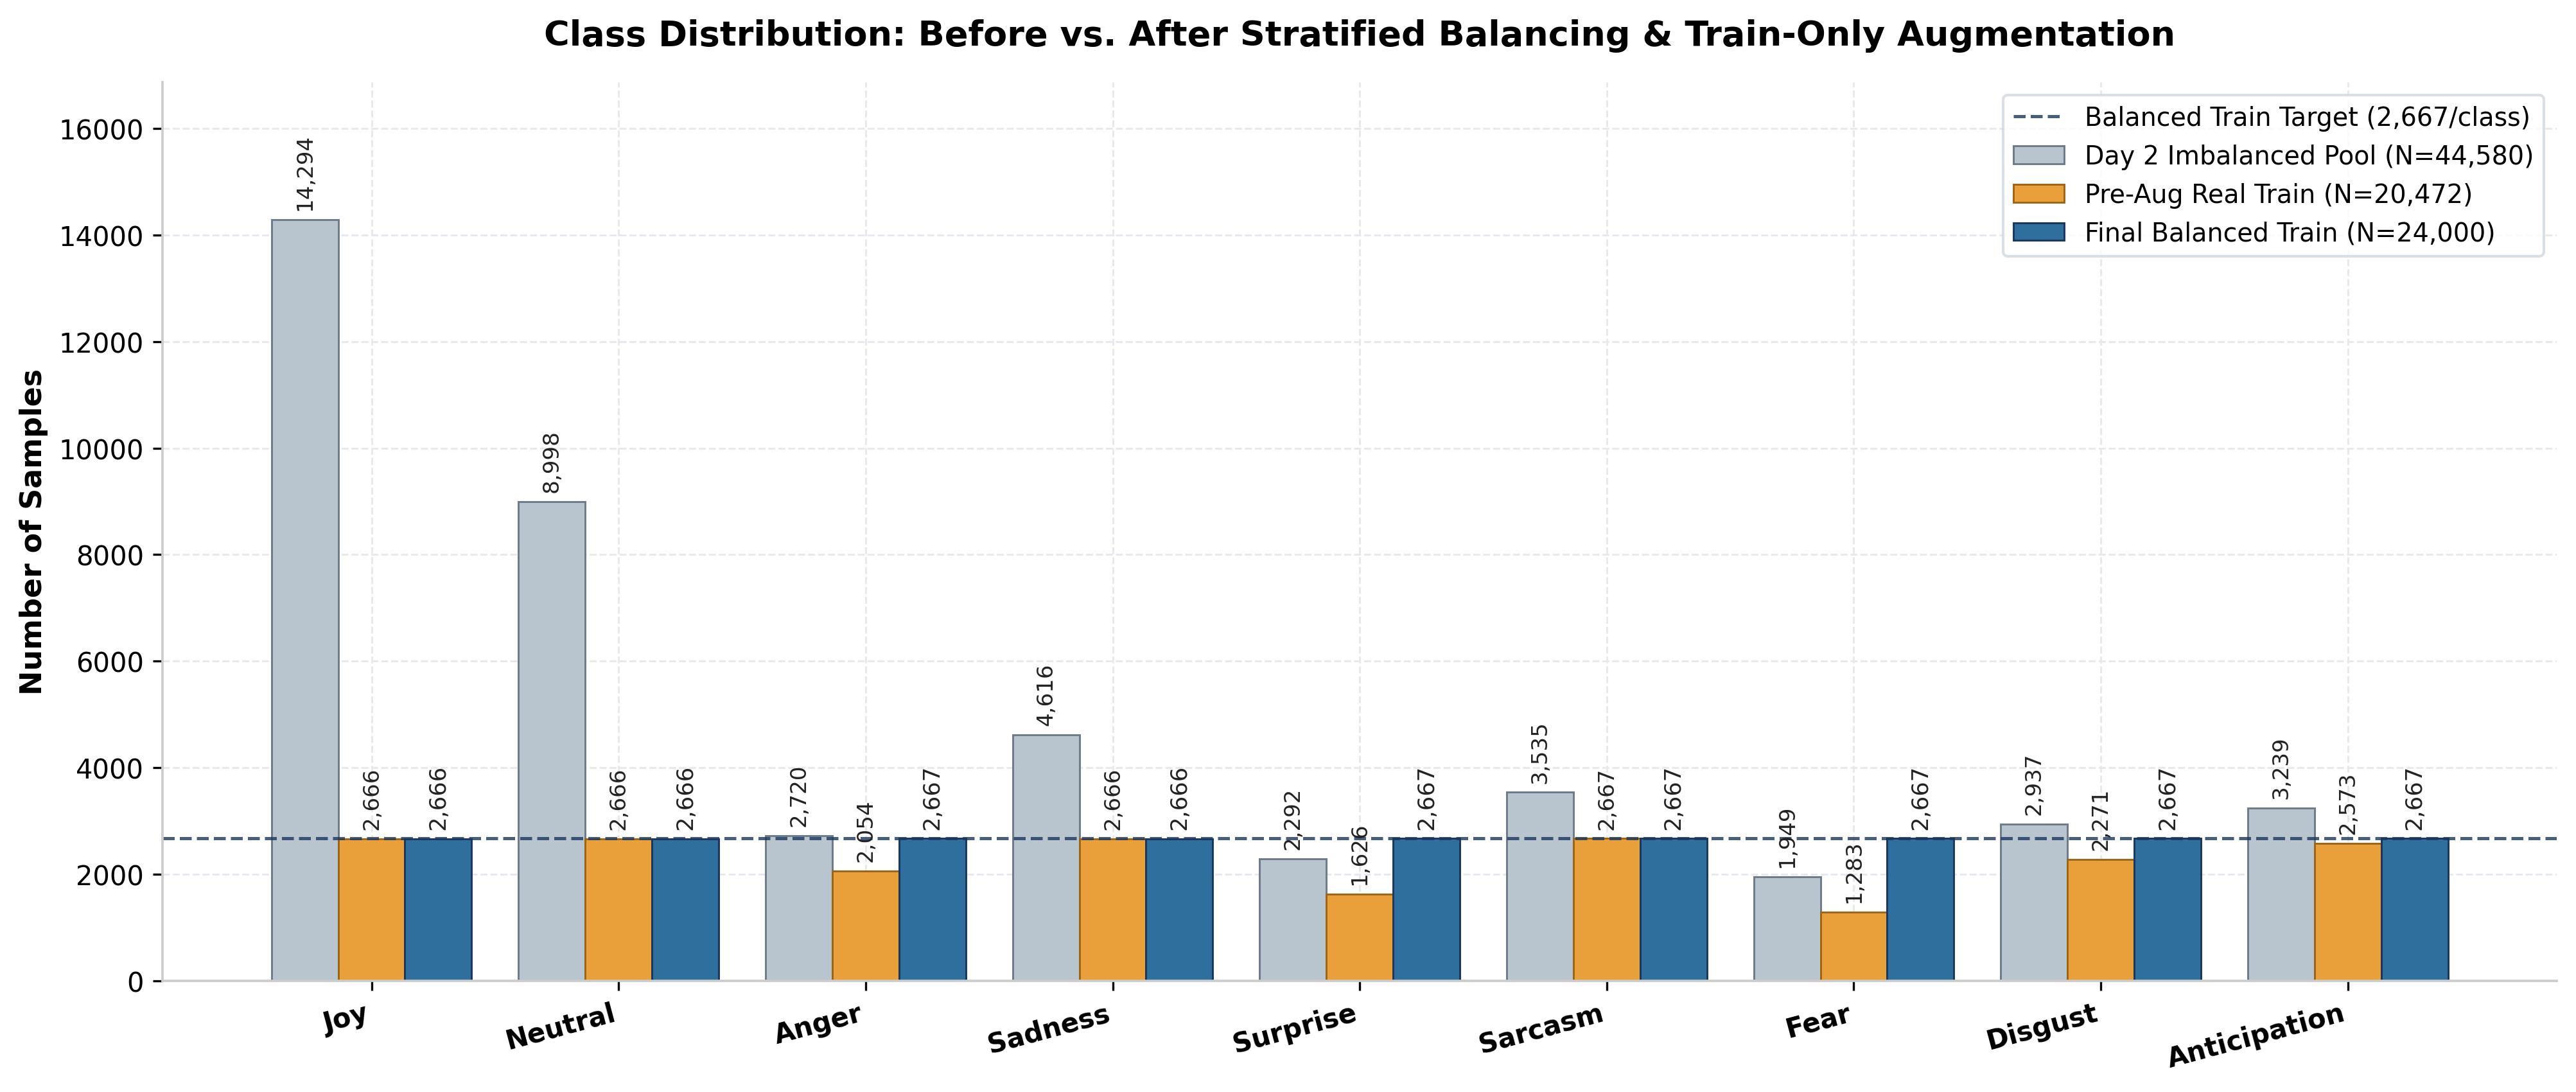

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/01_eda_charts/01_class_distribution_before_vs_after.png


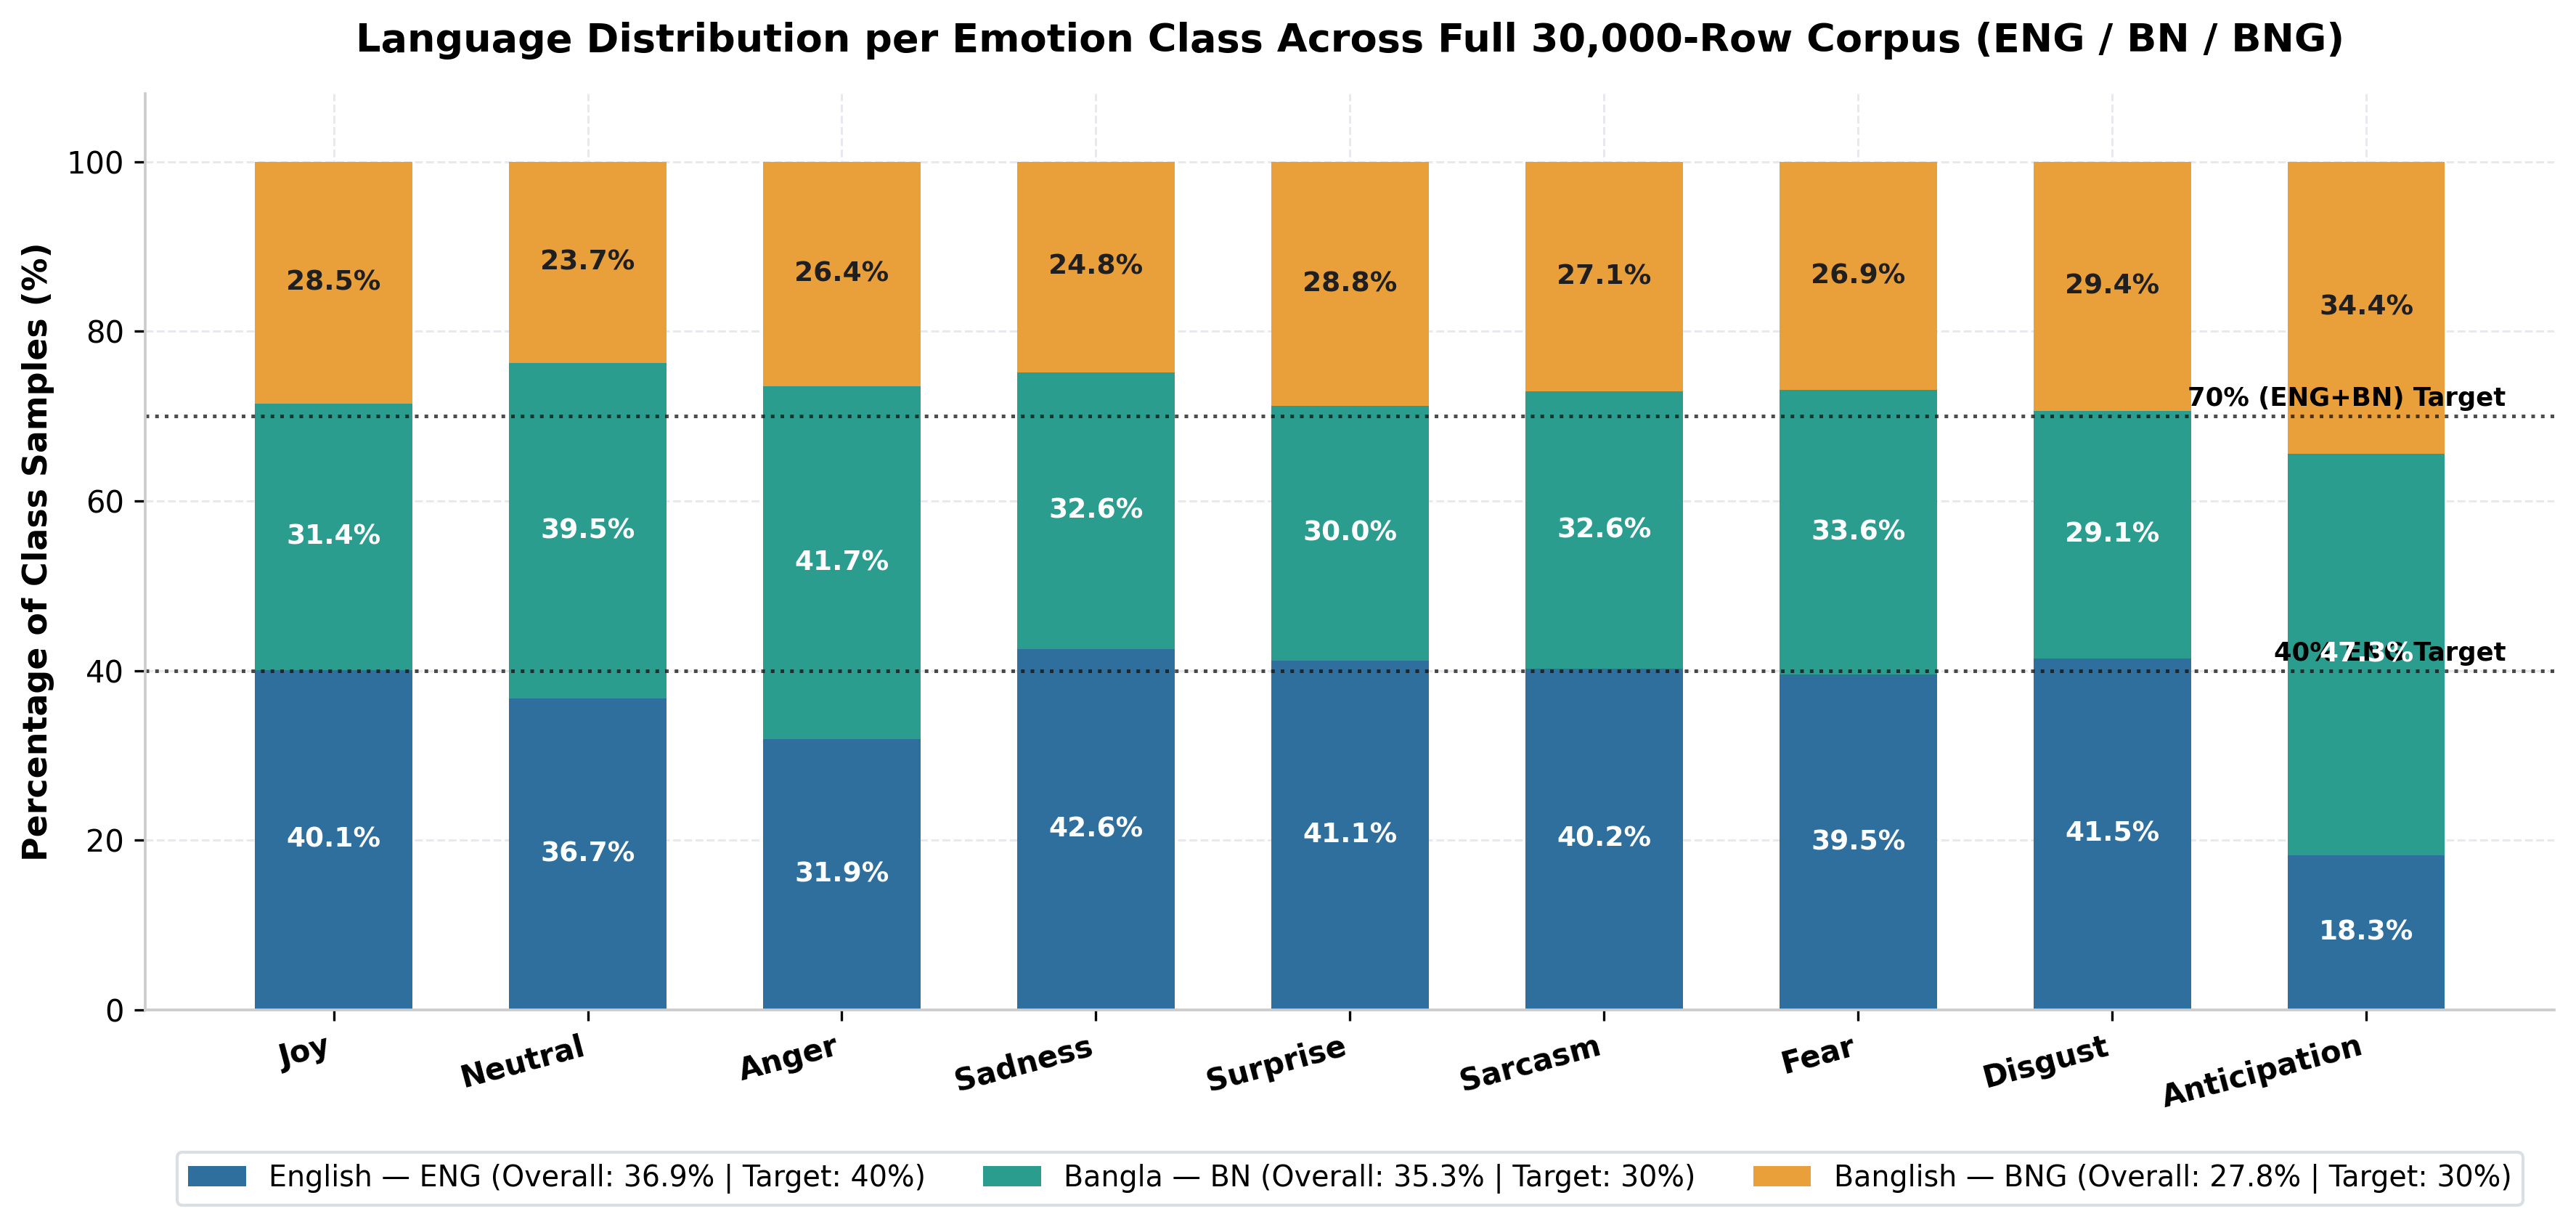

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/01_eda_charts/02_language_distribution_per_class.png


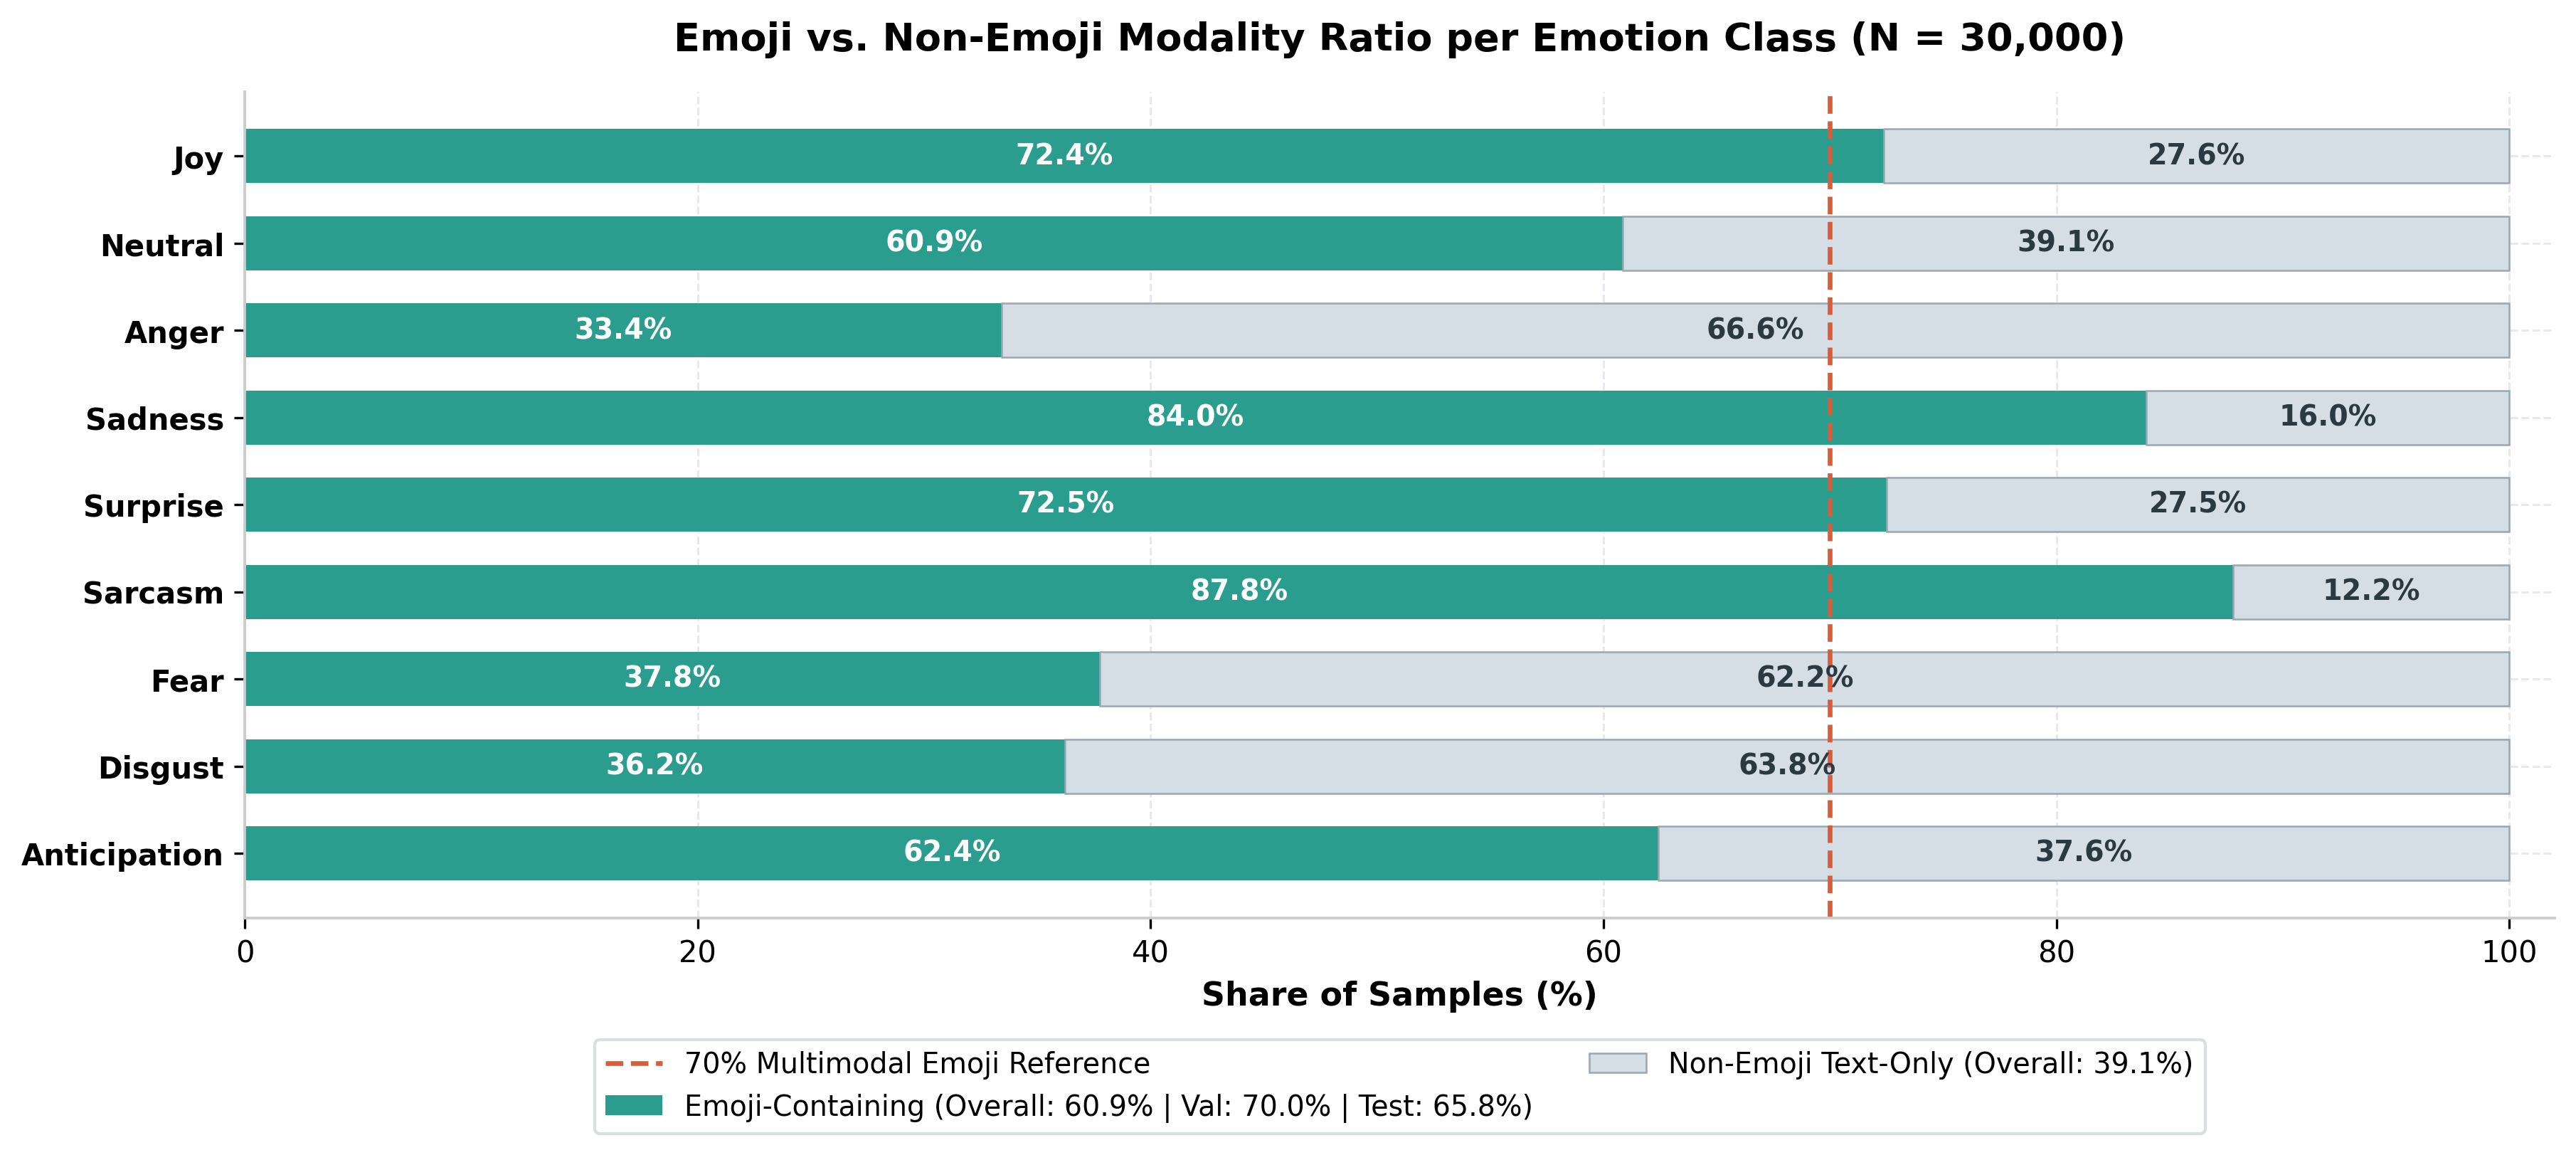

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/01_eda_charts/03_emoji_vs_non_emoji_per_class.png


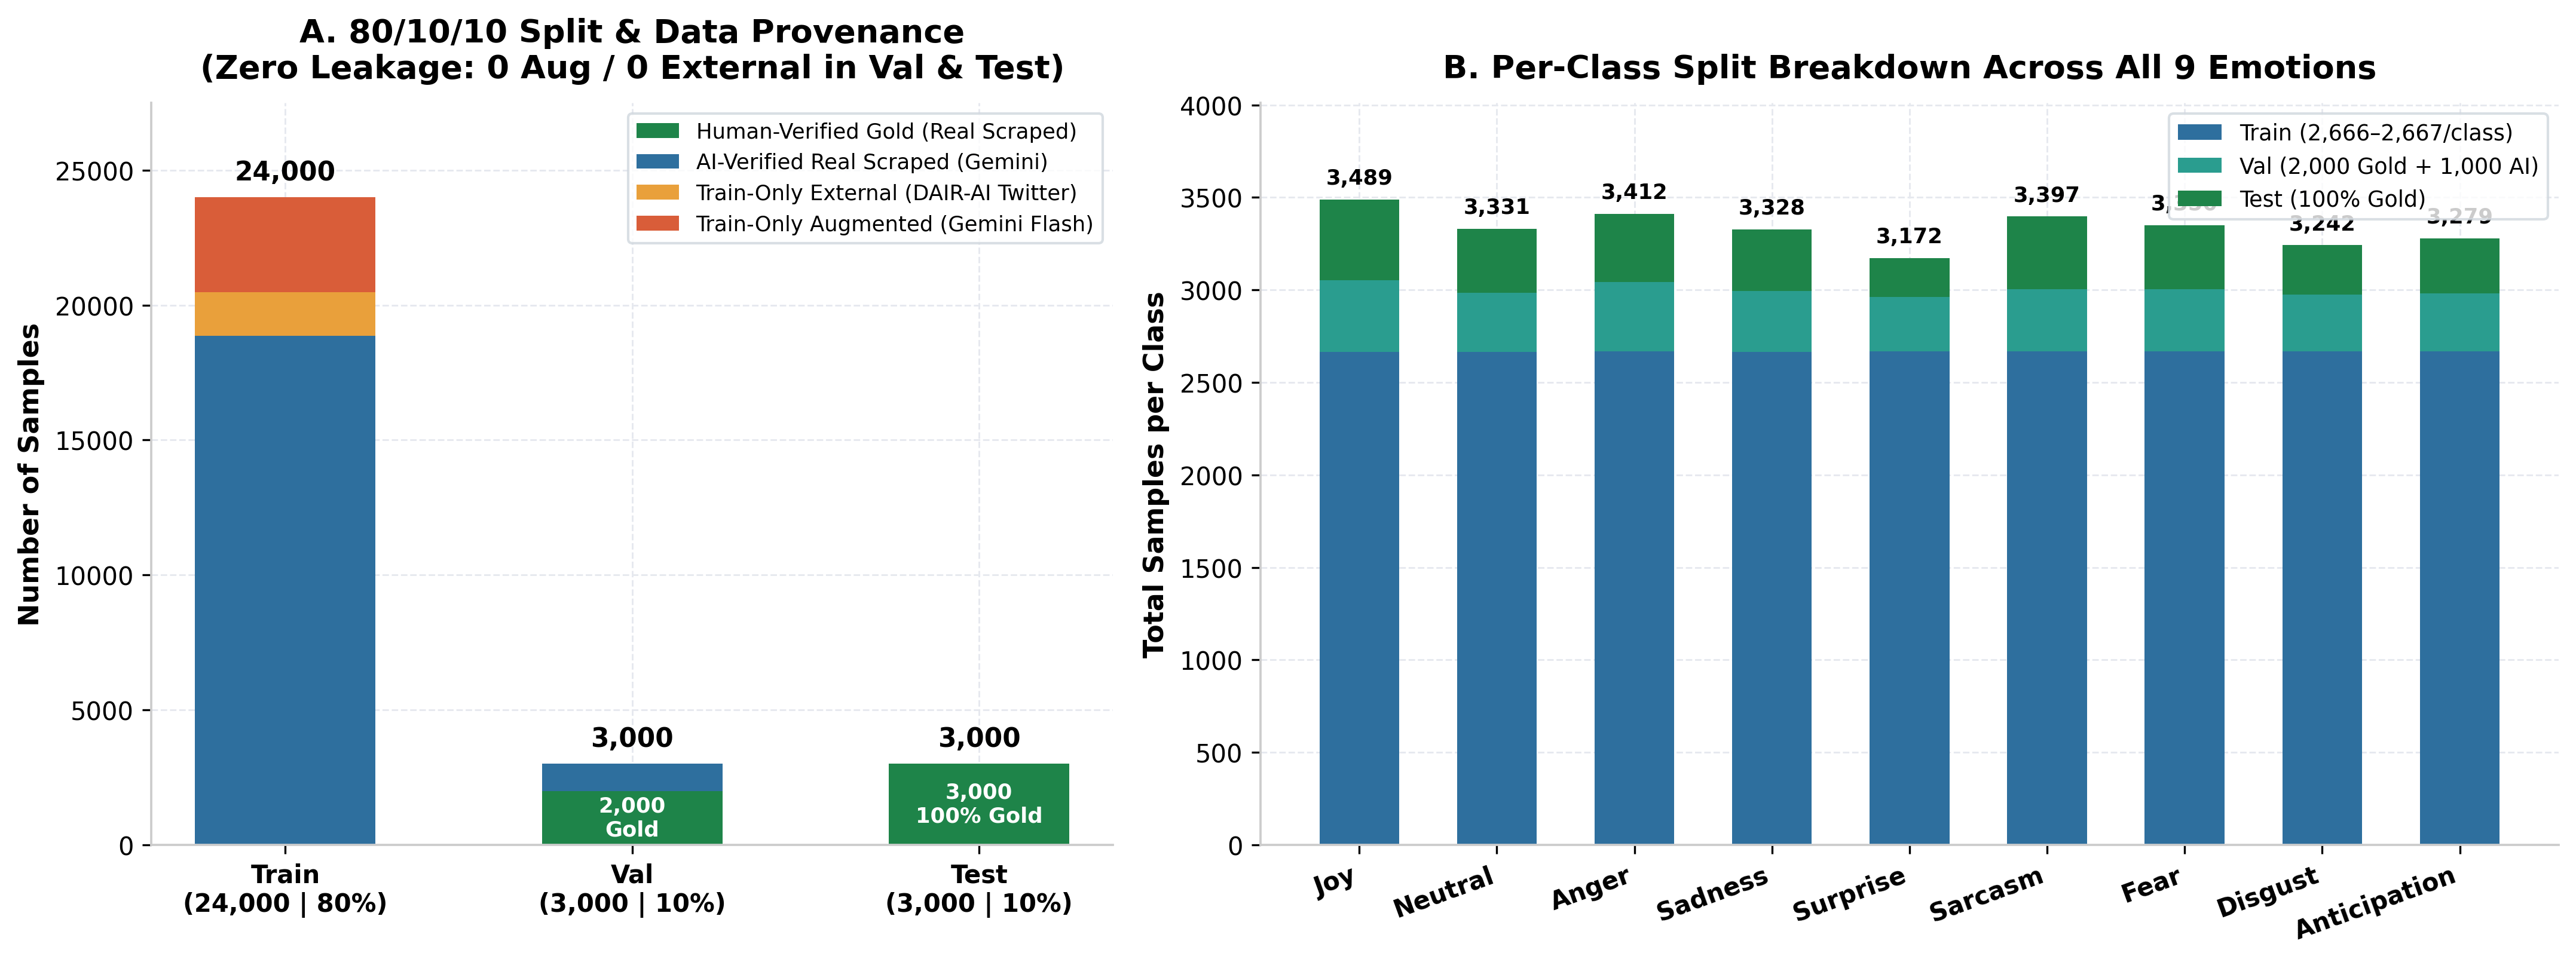

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/01_eda_charts/04_train_val_test_split_breakdown.png


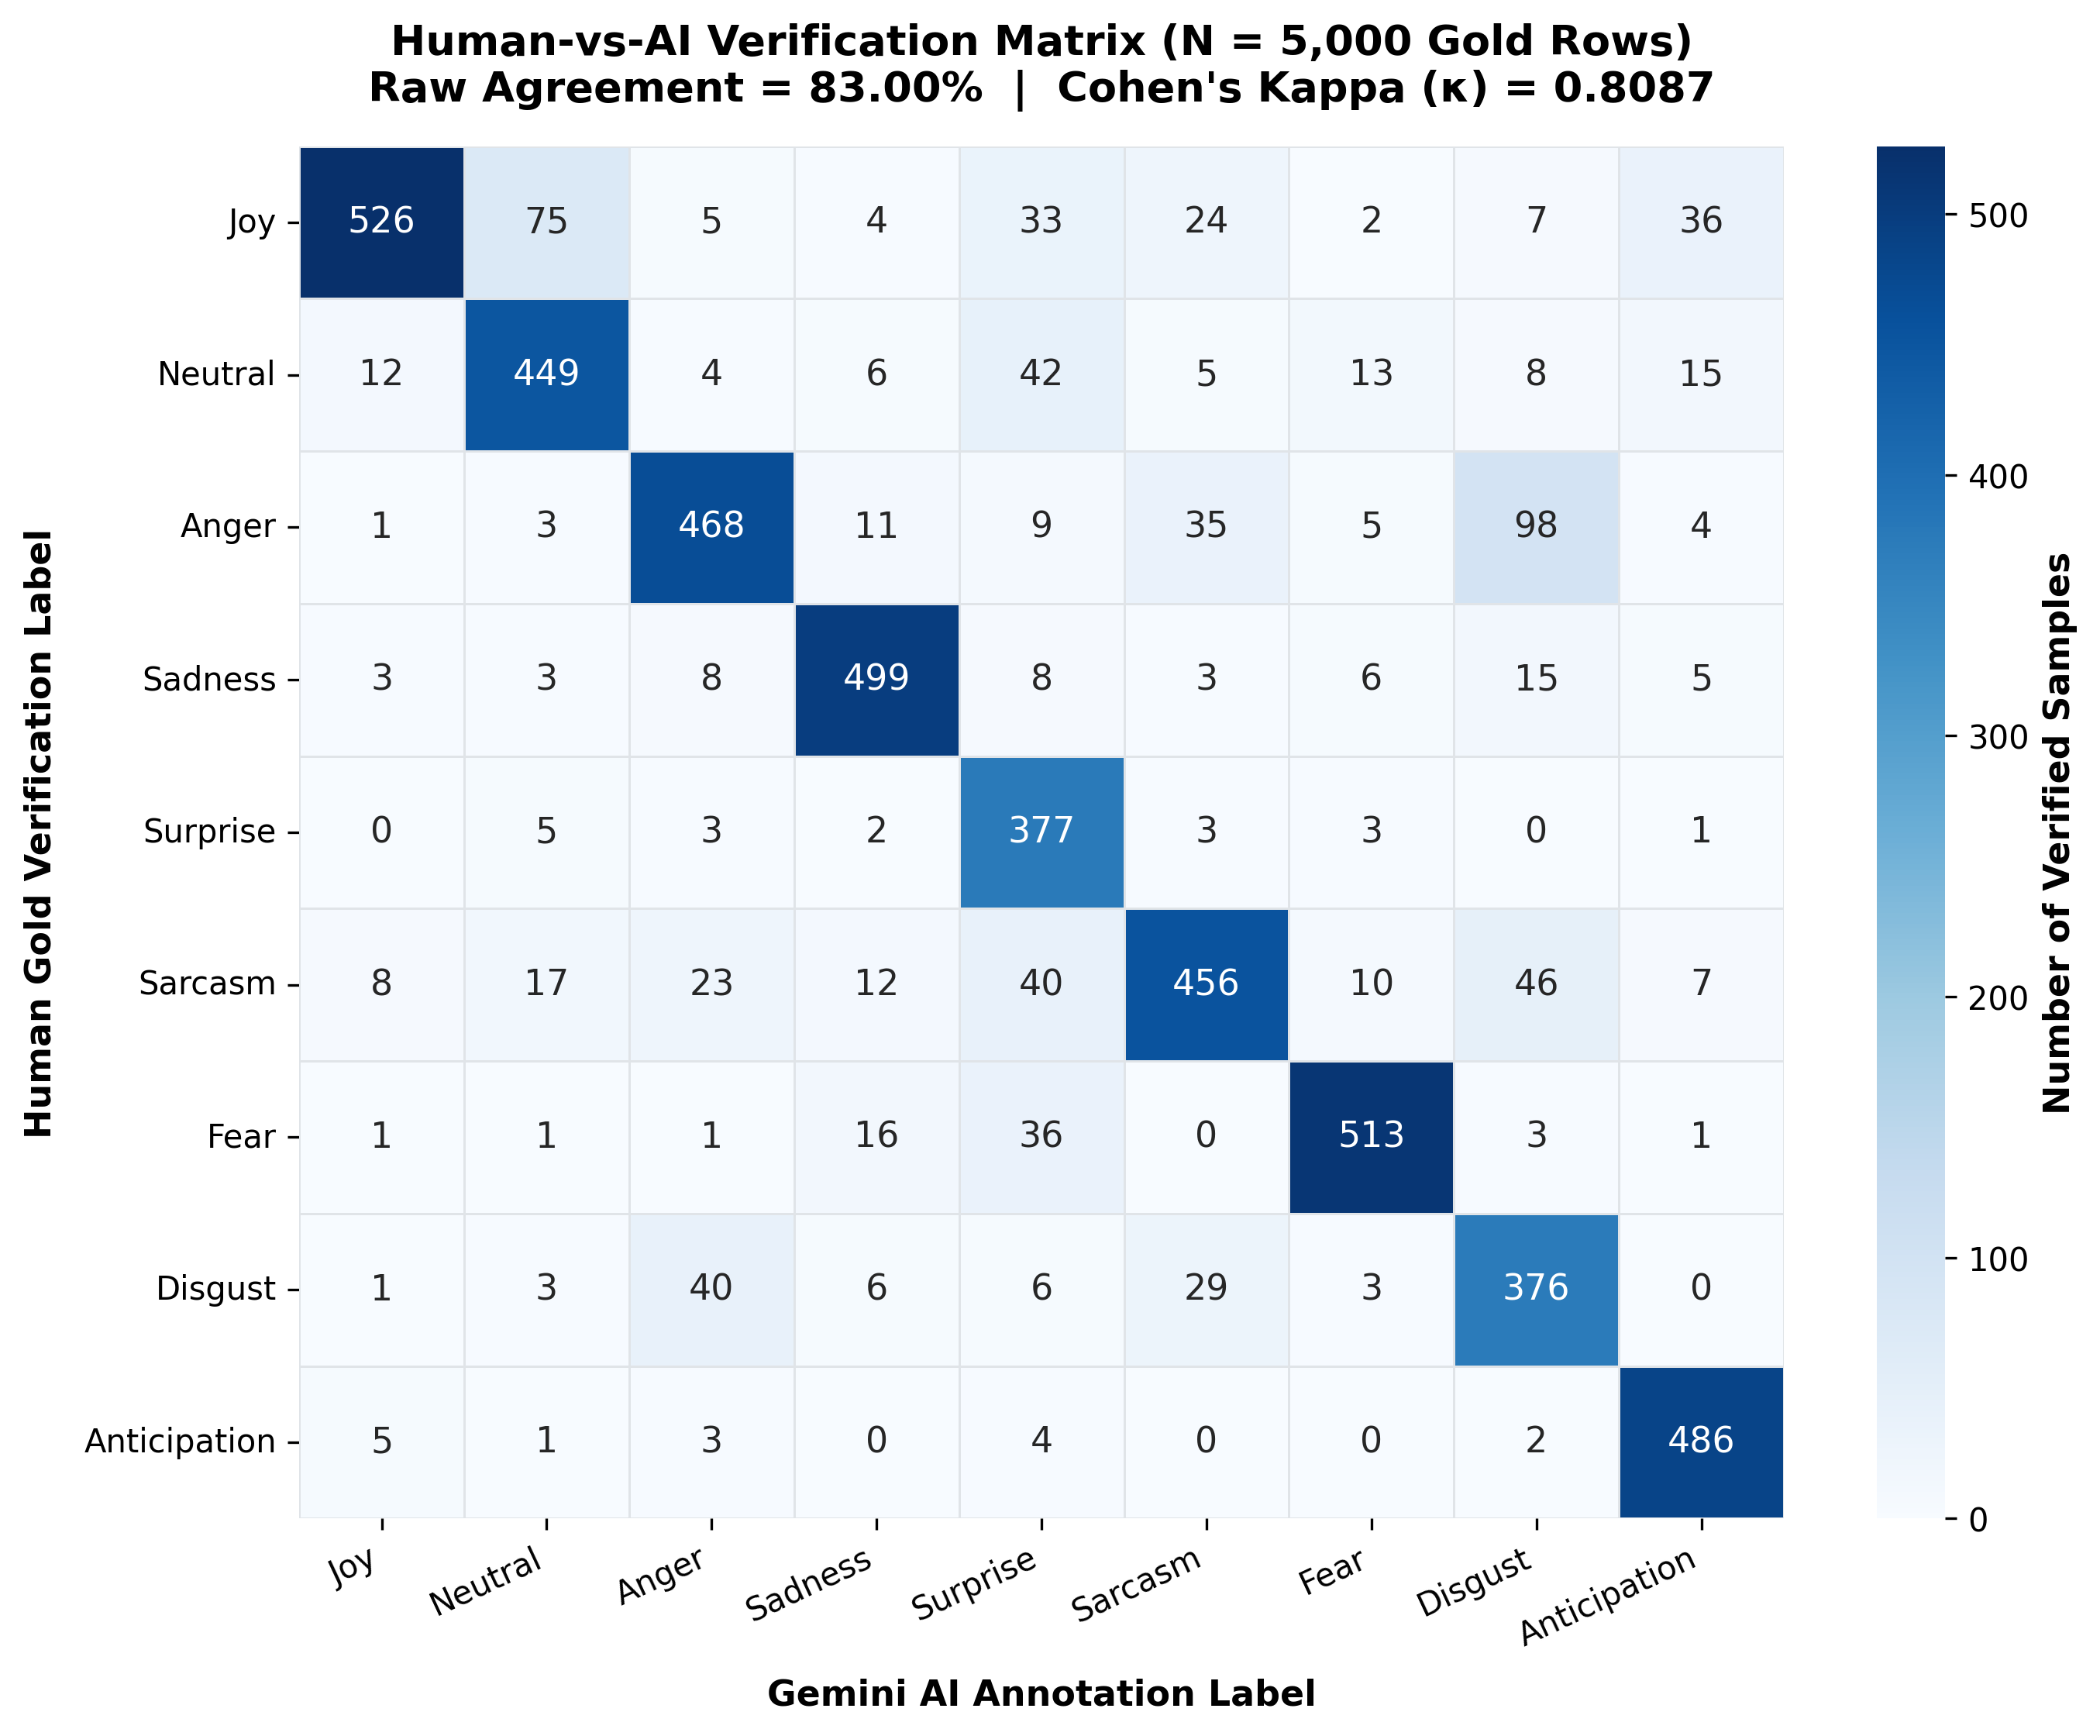

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/01_eda_charts/05_gold_5k_cohens_kappa_heatmap.png

=== STAGE 1 EDA CHARTS SAVED TO GOOGLE DRIVE ===


In [3]:
# ==============================================================================
# STAGE 1: GENERATE ALL 4 REQUIRED (+1 BONUS) WHITE-BACKGROUND EDA CHARTS
# ==============================================================================
def run_stage1_eda_charts():
    df_tr = load_split_compact(TRAIN_PQ, TRAIN_CSV)
    df_va = load_split_compact(VAL_PQ,   VAL_CSV)
    df_te = load_split_compact(TEST_PQ,  TEST_CSV)
    df_tr["split"], df_va["split"], df_te["split"] = "Train (80%)", "Val (10%)", "Test (10%)"
    df_all = pd.concat([df_tr, df_va, df_te], ignore_index=True)

    # Load Day 2 / Day 3 stage logs for Before vs. After balancing counts
    split_rep_path = os.path.join(DIRS['day3_logs'], 'stage1_split_report.json')
    day2_rep_path  = os.path.join(DIRS['day2_logs'], 'day2_stage3_audit_report.json')

    before_day2, pre_aug_train = {}, {}
    if os.path.exists(split_rep_path):
        with open(split_rep_path, "r", encoding="utf-8") as f:
            s1_rep = json.load(f)
        for c in CLASSES:
            before_day2[c]   = int(s1_rep["per_class"][c]["total_available"])
            pre_aug_train[c] = int(s1_rep["per_class"][c]["train_pre_aug_real"])
    elif os.path.exists(day2_rep_path):
        with open(day2_rep_path, "r", encoding="utf-8") as f:
            d2_rep = json.load(f)
        for item in d2_rep.get("per_class_summary", []):
            before_day2[item["class"]] = int(item["real_conf_ge3"])
        for c in CLASSES:
            pre_aug_train[c] = int(((df_tr["label"] == c) & (df_tr["is_augmented"] == 0)).sum())
    else:
        for c in CLASSES:
            pre_aug_train[c] = int(((df_tr["label"] == c) & (df_tr["is_augmented"] == 0)).sum())
            before_day2[c]   = pre_aug_train[c] + int((df_va["label"] == c).sum()) + int((df_te["label"] == c).sum())

    after_train = {c: int((df_tr["label"] == c).sum()) for c in CLASSES}

    C_NAVY, C_BLUE, C_TEAL, C_AMBER, C_CORAL, C_LIGHT = "#1B365D", "#2E6F9E", "#2A9D8F", "#E9A03B", "#D95D39", "#B8C4CE"

    # 1. Class Distribution: Before vs. After Balancing / Augmentation
    fig, ax = plt.subplots(figsize=(13.5, 5.8), dpi=300)
    x = np.arange(len(CLASSES)); w = 0.27
    vals_before = [before_day2[c] for c in CLASSES]
    vals_preaug = [pre_aug_train[c] for c in CLASSES]
    vals_after  = [after_train[c] for c in CLASSES]

    b1 = ax.bar(x - w, vals_before, width=w, color=C_LIGHT, edgecolor="#6C7A89", linewidth=0.7, label=f"Day 2 Imbalanced Pool (N={sum(vals_before):,})")
    b2 = ax.bar(x,     vals_preaug, width=w, color=C_AMBER, edgecolor="#9C6515", linewidth=0.7, label=f"Pre-Aug Real Train (N={sum(vals_preaug):,})")
    b3 = ax.bar(x + w, vals_after,  width=w, color=C_BLUE,  edgecolor=C_NAVY,    linewidth=0.7, label=f"Final Balanced Train (N={sum(vals_after):,})")
    ax.axhline(2667, color=C_NAVY, linestyle="--", linewidth=1.2, alpha=0.8, label="Balanced Train Target (2,667/class)")

    for bars, dy, fsz in [(b1, 180, 8.2), (b2, 180, 8.2), (b3, 180, 8.5)]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h + dy, f"{int(h):,}", ha="center", va="bottom", fontsize=fsz, rotation=90, color="#222222")

    ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=15, ha="right", fontweight="bold")
    ax.set_ylabel("Number of Samples"); ax.set_ylim(0, max(vals_before) * 1.18)
    ax.set_title("Class Distribution: Before vs. After Stratified Balancing & Train-Only Augmentation", pad=14)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(loc="upper right", frameon=True, fontsize=9.5)
    plt.tight_layout()
    p1 = os.path.join(DIRS['eda_charts'], "01_class_distribution_before_vs_after.png")
    fig.savefig(p1, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p1}")

    # 2. Language Distribution per Class (40/30/30)
    lang_ct = pd.crosstab(df_all["label"], df_all["language_tag"]).reindex(CLASSES)[["ENG", "BN", "BNG"]].fillna(0)
    lang_pct = lang_ct.div(lang_ct.sum(axis=1), axis=0) * 100.0
    overall_lang_pct = (df_all["language_tag"].value_counts(normalize=True) * 100.0).to_dict()

    fig, ax = plt.subplots(figsize=(12.5, 5.8), dpi=300)
    p_eng, p_bn, p_bng = lang_pct["ENG"].values, lang_pct["BN"].values, lang_pct["BNG"].values
    ax.bar(x, p_eng, width=0.62, color=C_BLUE,  label=f"English — ENG (Overall: {overall_lang_pct.get('ENG',0):.1f}% | Target: 40%)")
    ax.bar(x, p_bn,  width=0.62, bottom=p_eng, color=C_TEAL,  label=f"Bangla — BN (Overall: {overall_lang_pct.get('BN',0):.1f}% | Target: 30%)")
    ax.bar(x, p_bng, width=0.62, bottom=p_eng + p_bn, color=C_AMBER, label=f"Banglish — BNG (Overall: {overall_lang_pct.get('BNG',0):.1f}% | Target: 30%)")
    ax.axhline(40, color="#111111", linestyle=":", linewidth=1.2, alpha=0.75)
    ax.axhline(70, color="#111111", linestyle=":", linewidth=1.2, alpha=0.75)
    ax.text(len(CLASSES)-0.45, 41.2, "40% ENG Target", fontsize=8.5, ha="right", fontweight="bold")
    ax.text(len(CLASSES)-0.45, 71.2, "70% (ENG+BN) Target", fontsize=8.5, ha="right", fontweight="bold")

    for i in range(len(CLASSES)):
        if p_eng[i] >= 8: ax.text(i, p_eng[i]/2, f"{p_eng[i]:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        if p_bn[i]  >= 8: ax.text(i, p_eng[i] + p_bn[i]/2, f"{p_bn[i]:.1f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        if p_bng[i] >= 8: ax.text(i, p_eng[i] + p_bn[i] + p_bng[i]/2, f"{p_bng[i]:.1f}%", ha="center", va="center", color="#1F1F1F", fontsize=9, fontweight="bold")

    ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=15, ha="right", fontweight="bold")
    ax.set_ylabel("Percentage of Class Samples (%)"); ax.set_ylim(0, 108)
    ax.set_title("Language Distribution per Emotion Class Across Full 30,000-Row Corpus (ENG / BN / BNG)", pad=14)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=True, fontsize=9.5)
    plt.tight_layout()
    p2 = os.path.join(DIRS['eda_charts'], "02_language_distribution_per_class.png")
    fig.savefig(p2, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p2}")

    # 3. Emoji vs. Non-Emoji Ratio per Class (70/30 Reference)
    emo_ct = pd.crosstab(df_all["label"], df_all["has_emoji"]).reindex(CLASSES).fillna(0)
    emo_pct = (emo_ct[1] / emo_ct.sum(axis=1) * 100.0).values
    non_pct = 100.0 - emo_pct
    overall_emo = float(df_all["has_emoji"].mean() * 100.0)

    fig, ax = plt.subplots(figsize=(12.2, 5.6), dpi=300)
    y = np.arange(len(CLASSES))
    ax.barh(y, emo_pct, height=0.62, color=C_TEAL, label=f"Emoji-Containing (Overall: {overall_emo:.1f}% | Val: {df_va['has_emoji'].mean()*100:.1f}% | Test: {df_te['has_emoji'].mean()*100:.1f}%)")
    ax.barh(y, non_pct, height=0.62, left=emo_pct, color="#D5DDE5", edgecolor="#9AA7B2", linewidth=0.6, label=f"Non-Emoji Text-Only (Overall: {100-overall_emo:.1f}%)")
    ax.axvline(70.0, color=C_CORAL, linestyle="--", linewidth=1.6, label="70% Multimodal Emoji Reference")

    for i in range(len(CLASSES)):
        ax.text(emo_pct[i]/2, i, f"{emo_pct[i]:.1f}%", ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
        if non_pct[i] >= 10:
            ax.text(emo_pct[i] + non_pct[i]/2, i, f"{non_pct[i]:.1f}%", ha="center", va="center", color="#2B3A42", fontsize=9.5, fontweight="bold")

    ax.set_yticks(y); ax.set_yticklabels(CLASSES, fontweight="bold"); ax.invert_yaxis()
    ax.set_xlabel("Share of Samples (%)"); ax.set_xlim(0, 102)
    ax.set_title("Emoji vs. Non-Emoji Modality Ratio per Emotion Class (N = 30,000)", pad=14)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=True, fontsize=9.5)
    plt.tight_layout()
    p3 = os.path.join(DIRS['eda_charts'], "03_emoji_vs_non_emoji_per_class.png")
    fig.savefig(p3, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p3}")

    # 4. Train / Val / Test Split Breakdown (80/10/10) + Provenance
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.5), dpi=300, gridspec_kw={"width_ratios": [1.0, 1.35]})
    splits_lbl = ["Train\n(24,000 | 80%)", "Val\n(3,000 | 10%)", "Test\n(3,000 | 10%)"]
    tr_scraped_real = int(((df_tr["is_augmented"] == 0) & (df_tr["is_external_train_only"] == 0)).sum())
    tr_ext_real     = int(((df_tr["is_augmented"] == 0) & (df_tr["is_external_train_only"] == 1)).sum())
    tr_aug          = int((df_tr["is_augmented"] == 1).sum())
    va_gold = int(df_va["is_human_verified"].sum()) if "is_human_verified" in df_va.columns else 2000
    te_gold = int(df_te["is_human_verified"].sum()) if "is_human_verified" in df_te.columns else 3000

    cat_gold    = np.array([0, va_gold, te_gold])
    cat_scraped = np.array([tr_scraped_real, len(df_va)-va_gold, len(df_te)-te_gold])
    cat_ext     = np.array([tr_ext_real, 0, 0])
    cat_aug     = np.array([tr_aug, 0, 0])

    sx = np.arange(3)
    ax1.bar(sx, cat_gold,    width=0.52, color="#1E8449", label="Human-Verified Gold (Real Scraped)")
    ax1.bar(sx, cat_scraped, width=0.52, bottom=cat_gold, color=C_BLUE, label="AI-Verified Real Scraped (Gemini)")
    ax1.bar(sx, cat_ext,     width=0.52, bottom=cat_gold+cat_scraped, color=C_AMBER, label="Train-Only External (DAIR-AI Twitter)")
    ax1.bar(sx, cat_aug,     width=0.52, bottom=cat_gold+cat_scraped+cat_ext, color=C_CORAL, label="Train-Only Augmented (Gemini Flash)")

    for i, tot in enumerate([len(df_tr), len(df_va), len(df_te)]):
        ax1.text(i, tot + 450, f"{tot:,}", ha="center", va="bottom", fontweight="bold", fontsize=10.5)
    ax1.text(1, va_gold/2, f"{va_gold:,}\nGold", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    ax1.text(2, te_gold/2, f"{te_gold:,}\n100% Gold", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    ax1.set_xticks(sx); ax1.set_xticklabels(splits_lbl, fontweight="bold")
    ax1.set_ylabel("Number of Samples"); ax1.set_ylim(0, 27500)
    ax1.set_title("A. 80/10/10 Split & Data Provenance\n(Zero Leakage: 0 Aug / 0 External in Val & Test)", pad=10)
    ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False)
    ax1.legend(loc="upper right", fontsize=8.5)

    cx = np.arange(len(CLASSES))
    tr_c = [int((df_tr["label"] == c).sum()) for c in CLASSES]
    va_c = [int((df_va["label"] == c).sum()) for c in CLASSES]
    te_c = [int((df_te["label"] == c).sum()) for c in CLASSES]
    ax2.bar(cx, tr_c, width=0.58, color=C_BLUE,  label="Train (2,666–2,667/class)")
    ax2.bar(cx, va_c, width=0.58, bottom=tr_c, color=C_TEAL, label="Val (2,000 Gold + 1,000 AI)")
    ax2.bar(cx, te_c, width=0.58, bottom=np.array(tr_c)+np.array(va_c), color="#1E8449", label="Test (100% Gold)")
    for i in range(len(CLASSES)):
        ax2.text(i, tr_c[i]+va_c[i]+te_c[i] + 60, f"{tr_c[i]+va_c[i]+te_c[i]:,}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    ax2.set_xticks(cx); ax2.set_xticklabels(CLASSES, rotation=20, ha="right", fontweight="bold")
    ax2.set_ylabel("Total Samples per Class")
    ax2.set_ylim(0, max(tr_c[i]+va_c[i]+te_c[i] for i in range(len(CLASSES))) * 1.15)
    ax2.set_title("B. Per-Class Split Breakdown Across All 9 Emotions", pad=10)
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)
    ax2.legend(loc="upper right", fontsize=8.8)

    plt.tight_layout()
    p4 = os.path.join(DIRS['eda_charts'], "04_train_val_test_split_breakdown.png")
    fig.savefig(p4, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p4}")

    # 5. Bonus: 5,000-Row Gold Verification Heatmap (Cohen's Kappa)
    gold_5k_csv = os.path.join(DIRS['day3_gold'], "gold_5000_combined_verified.csv")
    if os.path.exists(gold_5k_csv):
        from sklearn.metrics import cohen_kappa_score
        df_g5 = pd.read_csv(gold_5k_csv)
        cm5 = confusion_matrix(df_g5["human_label"], df_g5["ai_label"], labels=CLASSES)
        k5  = cohen_kappa_score(df_g5["human_label"], df_g5["ai_label"], labels=CLASSES)
        acc5 = accuracy_score(df_g5["human_label"], df_g5["ai_label"]) * 100.0
        fig, ax = plt.subplots(figsize=(9.5, 7.6), dpi=300)
        sns.heatmap(cm5, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
                    linewidths=0.6, linecolor="#E0E4E8", cbar_kws={"label": "Number of Verified Samples"}, ax=ax)
        ax.set_xlabel("Gemini AI Annotation Label", fontweight="bold", labelpad=8)
        ax.set_ylabel("Human Gold Verification Label", fontweight="bold", labelpad=8)
        ax.set_title(f"Human-vs-AI Verification Matrix (N = {len(df_g5):,} Gold Rows)\nRaw Agreement = {acc5:.2f}%  |  Cohen's Kappa (κ) = {k5:.4f}", pad=14)
        plt.xticks(rotation=25, ha="right"); plt.yticks(rotation=0)
        plt.tight_layout()
        p5 = os.path.join(DIRS['eda_charts'], "05_gold_5k_cohens_kappa_heatmap.png")
        fig.savefig(p5, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
        print(f"  [SAVED] {p5}")
        del df_g5

    eda_stats = {
        "generated_at": datetime.now(timezone.utc).isoformat(),
        "total_rows": int(len(df_all)),
        "split_sizes": {"train": int(len(df_tr)), "val": int(len(df_va)), "test": int(len(df_te))},
        "overall_language_pct": {k: round(v, 2) for k, v in overall_lang_pct.items()},
        "overall_emoji_pct": round(overall_emo, 2),
        "human_verified_rows": {"val": va_gold, "test": te_gold, "total": va_gold + te_gold},
    }
    with open(CONFIG["EDA_SUMMARY_JSON"], "w", encoding="utf-8") as f:
        json.dump(eda_stats, f, indent=2)
    print("\n=== STAGE 1 EDA CHARTS SAVED TO GOOGLE DRIVE ===")
    del df_tr, df_va, df_te, df_all
    gc.collect()

run_stage1_eda_charts()


## Stage 2 — Baseline A: `CNN-BiLSTM` Early Fusion (Adapted from Kusal et al., 2025 [1])

> **Before running Stages 2–5:** Confirm Colab is on **T4 GPU** (`Runtime → Change runtime type → T4 GPU`).

### Faithful Replication of Kusal et al. (2025) [1] Adapted for Multilingual (`ENG`/`BN`/`BNG`):
- **Text Stream (`128`-d embeddings):** Tokenizes `text_stream` with the multilingual subword tokenizer (`xlm-roberta-base` SentencePiece vocabulary restricted to active `train_24k` tokens, `min_freq=2`), replacing English-only Google News NNLM (`d=128`) so Bangla and Banglish words are never lost as OOV.
- **Emoji Stream (`300`-d embeddings):** Dedicated `300`-d Emoji Embedding layer (matching `Emoji2Vec` dimensionality in Kusal et al. [1]) over extracted `emoji_stream` tokens, mean-pooled per sample (zero vector when no emoji is present).
- **Early Feature-Level Fusion ($C \in \mathbb{R}^{L \times 428}$):** Concatenates the `128`-d token embeddings with the `300`-d emoji representation at the input layer.
- **Hybrid Modality Encoder (Exact Kusal et al. Table 3 Hyperparameters):** `Conv1D(128 filters, kernel=5, padding=2, ReLU)` → `MaxPool1D(2)` → `Bi-LSTM(64 hidden units/dir = 128-d)` → `Dropout` → `Dense(64, ReLU)` → `9-class Softmax` trained with Adam (`lr=1e-3`, early stopping on Val Macro-F1).
- **Fast & Low-RAM:** Trains in **~2–3 minutes** on T4 GPU (< 1.5 GB VRAM) and saves `best_cnn_bilstm_kusal/` directly to Google Drive!


In [4]:
# ==============================================================================
# STAGE 2: BASELINE A — KUSAL ET AL. (2025) CNN-BiLSTM EARLY FUSION
# ==============================================================================
from transformers import AutoTokenizer

assert torch.cuda.is_available(), "No GPU detected! Switch Runtime -> T4 GPU, re-run Stage 0, then run Stage 2."

FORCE_RETRAIN_CNN = False

# Shared multilingual tokenizer (reused in Stages 2, 3, 4, 5)
tokenizer = AutoTokenizer.from_pretrained(CONFIG["MODEL_NAME"])

# Load compact DataFrames once for modeling stages (< 25 MB RAM total)
df_train_m = load_split_compact(TRAIN_PQ, TRAIN_CSV)
df_val_m   = load_split_compact(VAL_PQ,   VAL_CSV)
df_test_m  = load_split_compact(TEST_PQ,  TEST_CSV)

def build_cnn_vocabs(df_train: pd.DataFrame, tok, min_freq: int = 2) -> tuple:
    """Build compact active subword vocab & emoji vocab strictly from train_24k (zero leakage)."""
    tok_counter = Counter()
    for txt in df_train["text_stream"].fillna("").astype(str).tolist():
        ids = tok.encode(txt, add_special_tokens=False, truncation=True, max_length=CONFIG["MAX_LENGTH"])
        tok_counter.update(ids)
    # Filter FIRST, then enumerate so indices are strictly contiguous (2 .. len+1)
    active_tids = [tid for tid, cnt in tok_counter.items() if cnt >= min_freq]
    tok2idx = {str(tid): idx + 2 for idx, tid in enumerate(active_tids)}

    emo_counter = Counter()
    for estr in df_train["emoji_stream"].fillna("").astype(str).tolist():
        if estr.strip():
            emo_counter.update(estr.strip().split())
    active_emos = [e for e, cnt in emo_counter.items() if cnt >= 1]
    emo2idx = {e: idx + 2 for idx, e in enumerate(active_emos)}
    return tok2idx, emo2idx

class KusalCNNBiLSTMDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tok, tok2idx: dict, emo2idx: dict, max_len: int = 128):
        self.texts   = df["text_stream"].fillna("").astype(str).tolist()
        self.emojis  = df["emoji_stream"].fillna("").astype(str).tolist()
        self.labels  = df["label_id"].astype(int).tolist()
        self.tok     = tok
        self.tok2idx = tok2idx
        self.emo2idx = emo2idx
        self.max_len = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        raw_ids = self.tok.encode(self.texts[idx], add_special_tokens=False, truncation=True, max_length=self.max_len)
        t_ids = [self.tok2idx.get(str(t), 1) for t in raw_ids] or [1]
        estr = self.emojis[idx].strip()
        e_ids = [self.emo2idx.get(e, 1) for e in estr.split()[:8]] if estr else [0]
        return t_ids, e_ids, self.labels[idx]

def kusal_collate_fn(batch):
    t_seqs, e_seqs, labels = zip(*batch)
    # Pad text to at least 8 so Conv1D(kernel=5) + MaxPool1D(2) always have valid length
    max_t = max(8, max(len(s) for s in t_seqs))
    max_e = max(1, max(len(s) for s in e_seqs))
    t_pad = torch.zeros((len(batch), max_t), dtype=torch.long)
    e_pad = torch.zeros((len(batch), max_e), dtype=torch.long)
    for i, (ts, es) in enumerate(zip(t_seqs, e_seqs)):
        t_pad[i, :len(ts)] = torch.tensor(ts, dtype=torch.long)
        e_pad[i, :len(es)] = torch.tensor(es, dtype=torch.long)
    return t_pad, e_pad, torch.tensor(labels, dtype=torch.long)

class KusalCNNBiLSTMEarlyFusion(nn.Module):
    """
    Multilingual PyTorch implementation of Kusal et al. (2025) [1]:
      Text Emb (128-d) || Emoji Emb (300-d) -> 428-d Early Fusion
      -> Conv1D(128, k=5, ReLU) -> MaxPool1D(2) -> BiLSTM(64/dir = 128-d)
      -> Dropout -> Dense(64, ReLU) -> Dense(9)
    """
    def __init__(self, text_vocab_size: int, emoji_vocab_size: int, num_classes: int = 9):
        super().__init__()
        d_txt = CONFIG["CNN_TEXT_EMB_DIM"]   # 128
        d_emo = CONFIG["CNN_EMOJI_EMB_DIM"]  # 300
        self.text_emb  = nn.Embedding(text_vocab_size,  d_txt, padding_idx=0)
        self.emoji_emb = nn.Embedding(emoji_vocab_size, d_emo, padding_idx=0)
        self.emb_drop  = nn.Dropout(0.25)

        self.conv1d = nn.Conv1d(
            in_channels=d_txt + d_emo,
            out_channels=CONFIG["CNN_FILTERS"],
            kernel_size=CONFIG["CNN_KERNEL_SIZE"],
            padding=CONFIG["CNN_KERNEL_SIZE"] // 2,
        )
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=CONFIG["CNN_POOL_SIZE"])
        self.bilstm = nn.LSTM(
            input_size=CONFIG["CNN_FILTERS"],
            hidden_size=CONFIG["LSTM_HIDDEN"],
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )
        self.head = nn.Sequential(
            nn.Dropout(CONFIG["CNN_DROPOUT"]),
            nn.Linear(CONFIG["LSTM_HIDDEN"] * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, num_classes),
        )

    def forward(self, t_ids, e_ids):
        # Text embeddings: (B, L, 128)
        t_vec = self.text_emb(t_ids)
        # Masked mean-pooled Emoji embeddings: (B, 300) -> zero vector when no emoji!
        e_mask = (e_ids != 0).unsqueeze(-1).float()
        e_sum  = (self.emoji_emb(e_ids) * e_mask).sum(dim=1)
        e_cnt  = e_mask.sum(dim=1).clamp(min=1.0)
        e_vec  = (e_sum / e_cnt) * (e_mask.sum(dim=1) > 0).float()

        # Early Feature-Level Fusion: C = [f_1..f_128, e_1..e_300] -> (B, L, 428)
        e_exp = e_vec.unsqueeze(1).expand(-1, t_vec.size(1), -1)
        fused = self.emb_drop(torch.cat([t_vec, e_exp], dim=-1))

        # Conv1D(128, k=5) -> ReLU -> MaxPool1D(2)
        c_out = self.pool(self.relu(self.conv1d(fused.transpose(1, 2)))).transpose(1, 2)
        # Bi-LSTM (64/dir -> 128-d) -> Global Max+Mean pooling
        lstm_out, _ = self.bilstm(c_out)
        pooled = lstm_out.max(dim=1).values
        return self.head(pooled)

@torch.no_grad()
def evaluate_cnn_bilstm(model, loader, criterion):
    model.eval()
    tot_loss, preds, labels, probs = 0.0, [], [], []
    for t_ids, e_ids, y in loader:
        t_ids, e_ids, y = t_ids.to(device), e_ids.to(device), y.to(device)
        logits = model(t_ids, e_ids)
        tot_loss += criterion(logits, y).item() * y.size(0)
        p = torch.softmax(logits, dim=-1).cpu().numpy()
        probs.append(p)
        preds.extend(np.argmax(p, axis=-1).tolist())
        labels.extend(y.cpu().tolist())
    return {
        "loss": tot_loss / max(len(labels), 1),
        "accuracy": float(accuracy_score(labels, preds)),
        "macro_f1": float(f1_score(labels, preds, average="macro", zero_division=0)),
        "micro_f1": float(f1_score(labels, preds, average="micro", zero_division=0)),
        "weighted_f1": float(f1_score(labels, preds, average="weighted", zero_division=0)),
        "preds": np.array(preds, dtype=np.int64),
        "labels": np.array(labels, dtype=np.int64),
        "probs": np.vstack(probs),
    }

def run_stage2_train_cnn_bilstm():
    ckpt_pt   = os.path.join(DIRS["ckpt_cnn_bilstm"], "best_cnn_bilstm.pt")
    vocab_js  = os.path.join(DIRS["ckpt_cnn_bilstm"], "vocabs.json")

    if (not FORCE_RETRAIN_CNN) and os.path.exists(ckpt_pt) and os.path.exists(vocab_js) and os.path.exists(CONFIG["HIST_CNN_JSON"]):
        with open(CONFIG["HIST_CNN_JSON"], "r", encoding="utf-8") as f:
            h = json.load(f)
        print(f"[RESUME] Baseline A (CNN-BiLSTM Early Fusion) already trained on Drive! Best Val Macro-F1 = {h['best_val_macro_f1']:.4f} (Epoch {h['best_epoch']})")
        return

    seed_everything(CONFIG["RANDOM_SEED"])
    tok2idx, emo2idx = build_cnn_vocabs(df_train_m, tokenizer, min_freq=CONFIG["CNN_MIN_TOK_FREQ"])
    t_vocab_sz = len(tok2idx) + 2
    e_vocab_sz = len(emo2idx) + 2
    print(f"Built Train-only vocabularies -> Text subwords: {t_vocab_sz:,} | Emojis: {e_vocab_sz:,}")

    with open(vocab_js, "w", encoding="utf-8") as f:
        json.dump({"tok2idx": tok2idx, "emo2idx": emo2idx}, f, ensure_ascii=False)

    tr_loader = DataLoader(KusalCNNBiLSTMDataset(df_train_m, tokenizer, tok2idx, emo2idx, CONFIG["MAX_LENGTH"]),
                           batch_size=CONFIG["CNN_BATCH_SIZE"], shuffle=True, num_workers=CONFIG["NUM_WORKERS"],
                           pin_memory=True, collate_fn=kusal_collate_fn)
    va_loader = DataLoader(KusalCNNBiLSTMDataset(df_val_m, tokenizer, tok2idx, emo2idx, CONFIG["MAX_LENGTH"]),
                           batch_size=128, shuffle=False, num_workers=CONFIG["NUM_WORKERS"],
                           pin_memory=True, collate_fn=kusal_collate_fn)

    model = KusalCNNBiLSTMEarlyFusion(t_vocab_sz, e_vocab_sz, NUM_CLASSES).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["CNN_LR"], weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

    best_f1, best_ep, no_imp = -1.0, 0, 0
    history = {"model": "CNN-BiLSTM Early Fusion (Kusal et al., 2025)", "epochs": [], "best_val_macro_f1": 0.0, "best_epoch": 0}
    t0 = time.time()

    for ep in range(1, CONFIG["CNN_EPOCHS"] + 1):
        model.train()
        ep_loss = ep_corr = ep_n = 0
        for t_ids, e_ids, y in tr_loader:
            t_ids, e_ids, y = t_ids.to(device, non_blocking=True), e_ids.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(t_ids, e_ids)
            loss = criterion(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            ep_loss += loss.item() * y.size(0)
            ep_corr += (logits.argmax(dim=-1) == y).sum().item()
            ep_n    += y.size(0)

        va_res = evaluate_cnn_bilstm(model, va_loader, criterion)
        rec = {
            "epoch": ep,
            "train_loss": round(ep_loss / max(ep_n, 1), 4),
            "train_accuracy": round(ep_corr / max(ep_n, 1), 4),
            "val_loss": round(va_res["loss"], 4),
            "val_accuracy": round(va_res["accuracy"], 4),
            "val_macro_f1": round(va_res["macro_f1"], 4),
            "val_weighted_f1": round(va_res["weighted_f1"], 4),
        }
        history["epochs"].append(rec)

        tag = ""
        if va_res["macro_f1"] > best_f1:
            best_f1, best_ep, no_imp = va_res["macro_f1"], ep, 0
            history["best_val_macro_f1"] = round(best_f1, 4)
            history["best_epoch"] = best_ep
            torch.save({"model_state_dict": model.state_dict(), "text_vocab_size": t_vocab_sz, "emoji_vocab_size": e_vocab_sz}, ckpt_pt)
            tag = " ★ BEST SAVED"
        else:
            no_imp += 1

        print(f"  [CNN-BiLSTM Ep {ep:2d}/{CONFIG['CNN_EPOCHS']}] TrLoss:{rec['train_loss']:.4f} TrAcc:{rec['train_accuracy']*100:5.1f}% | ValLoss:{rec['val_loss']:.4f} ValAcc:{rec['val_accuracy']*100:5.2f}% ValMacroF1:{rec['val_macro_f1']:.4f}{tag}")
        with open(CONFIG["HIST_CNN_JSON"], "w", encoding="utf-8") as f:
            json.dump(history, f, indent=2)
        if no_imp >= CONFIG["CNN_PATIENCE"]:
            print(f"  Early stopping triggered at epoch {ep} (patience={CONFIG['CNN_PATIENCE']}).")
            break

    print(f"\n=== BASELINE A (CNN-BiLSTM) COMPLETE in {(time.time()-t0)/60:.1f} min | Best Val Macro-F1: {best_f1:.4f} (Ep {best_ep}) ===")
    del model, optimizer, tr_loader, va_loader
    torch.cuda.empty_cache()
    gc.collect()

run_stage2_train_cnn_bilstm()


Built Train-only vocabularies -> Text subwords: 13,943 | Emojis: 664
  [CNN-BiLSTM Ep  1/15] TrLoss:1.6631 TrAcc: 44.5% | ValLoss:1.7913 ValAcc:41.30% ValMacroF1:0.3918 ★ BEST SAVED
  [CNN-BiLSTM Ep  2/15] TrLoss:1.4950 TrAcc: 51.4% | ValLoss:1.7147 ValAcc:45.03% ValMacroF1:0.4383 ★ BEST SAVED
  [CNN-BiLSTM Ep  3/15] TrLoss:1.4303 TrAcc: 54.6% | ValLoss:1.7072 ValAcc:46.50% ValMacroF1:0.4592 ★ BEST SAVED
  [CNN-BiLSTM Ep  4/15] TrLoss:1.3658 TrAcc: 57.1% | ValLoss:1.6835 ValAcc:48.50% ValMacroF1:0.4730 ★ BEST SAVED
  [CNN-BiLSTM Ep  5/15] TrLoss:1.3058 TrAcc: 59.7% | ValLoss:1.6112 ValAcc:52.60% ValMacroF1:0.5172 ★ BEST SAVED
  [CNN-BiLSTM Ep  6/15] TrLoss:1.2468 TrAcc: 62.8% | ValLoss:1.6095 ValAcc:53.10% ValMacroF1:0.5267 ★ BEST SAVED
  [CNN-BiLSTM Ep  7/15] TrLoss:1.1910 TrAcc: 65.3% | ValLoss:1.5350 ValAcc:54.93% ValMacroF1:0.5439 ★ BEST SAVED
  [CNN-BiLSTM Ep  8/15] TrLoss:1.1404 TrAcc: 67.9% | ValLoss:1.5142 ValAcc:54.87% ValMacroF1:0.5442 ★ BEST SAVED
  [CNN-BiLSTM Ep  9/15] TrL

## Stage 3 & Stage 4 — Transformer Baselines (`xlm-roberta-base`): Text-Only vs. Early Fusion

Trains **two controlled Transformer baselines** under **identical hyperparameters and random seed (`42`)** so your ablation between Text-Only and Early Fusion is 100% apples-to-apples:
- **Stage 3 (Baseline B — `xlm-roberta-base` Text-Only):** Uses `text_stream` only (`use_demoji=False`). Directly satisfies your proposal's **unimodal text-only baseline** requirement (~12 min on T4).
- **Stage 4 (Baseline C — `xlm-roberta-base` Early Fusion):** Uses native XLM-R pair `<s> text_stream </s></s> demoji_text </s>` (`use_demoji=True`, `truncation="longest_first"`, `max_length=128`). Auto-resumes if already saved on Drive (~13 min on T4).

Both stages use **dynamic padding + FP16 mixed precision** (~4.2 GB peak VRAM / 15 GB T4), checkpoint after every epoch to Google Drive, and fully release GPU memory upon completion.


In [5]:
# ==============================================================================
# SHARED MEMORY-SAFE XLM-ROBERTA TRAINER (USED BY STAGE 3 & STAGE 4)
# ==============================================================================
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

class XLMRDataset(Dataset):
    """Supports both Unimodal Text-Only (`use_demoji=False`) and Early Fusion (`use_demoji=True`)."""
    def __init__(self, df: pd.DataFrame, tok, max_len: int = 128, use_demoji: bool = True):
        self.texts      = df["text_stream"].fillna("").astype(str).tolist()
        self.demojis    = df["demoji_text"].fillna("").astype(str).tolist()
        self.labels     = df["label_id"].astype(int).tolist()
        self.tok        = tok
        self.max_len    = max_len
        self.use_demoji = use_demoji

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        txt = self.texts[idx].strip()
        dem = self.demojis[idx].strip() if self.use_demoji else ""
        if dem:
            enc = self.tok(txt, dem, truncation="longest_first", max_length=self.max_len, padding=False)
        else:
            enc = self.tok(txt, truncation=True, max_length=self.max_len, padding=False)
        enc["labels"] = self.labels[idx]
        return enc

xlmr_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)

@torch.no_grad()
def evaluate_xlmr_loader(model, loader, criterion, use_fp16: bool = True):
    model.eval()
    tot_loss, preds, labels, probs = 0.0, [], [], []
    for batch in loader:
        y = batch.pop("labels").to(device, non_blocking=True)
        batch = {k: v.to(device, non_blocking=True) for k, v in batch.items()}
        with torch.amp.autocast("cuda", enabled=use_fp16):
            logits = model(**batch).logits
            loss   = criterion(logits, y)
        tot_loss += loss.item() * y.size(0)
        p = torch.softmax(logits.float(), dim=-1).cpu().numpy()
        probs.append(p)
        preds.extend(np.argmax(p, axis=-1).tolist())
        labels.extend(y.cpu().tolist())
    return {
        "loss": tot_loss / max(len(labels), 1),
        "accuracy": float(accuracy_score(labels, preds)),
        "macro_f1": float(f1_score(labels, preds, average="macro", zero_division=0)),
        "micro_f1": float(f1_score(labels, preds, average="micro", zero_division=0)),
        "weighted_f1": float(f1_score(labels, preds, average="weighted", zero_division=0)),
        "preds": np.array(preds, dtype=np.int64),
        "labels": np.array(labels, dtype=np.int64),
        "probs": np.vstack(probs),
    }

def train_xlmr_variant(
    run_title: str,
    use_demoji: bool,
    best_model_dir: str,
    history_json: str,
    resume_state_pt: str,
    force_retrain: bool = False,
):
    # Skip cleanly if already completed all epochs on Google Drive
    if (not force_retrain) and os.path.exists(history_json) and os.path.exists(os.path.join(best_model_dir, "config.json")):
        with open(history_json, "r", encoding="utf-8") as f:
            h = json.load(f)
        if len(h.get("epochs", [])) >= CONFIG["XLMR_EPOCHS"]:
            print(f"[RESUME] {run_title} already completed {len(h['epochs'])}/{CONFIG['XLMR_EPOCHS']} epochs on Drive!")
            print(f"  Best Val Macro-F1: {h['best_val_macro_f1']:.4f} (Epoch {h['best_epoch']})")
            return

    seed_everything(CONFIG["RANDOM_SEED"])
    tr_loader = DataLoader(XLMRDataset(df_train_m, tokenizer, CONFIG["MAX_LENGTH"], use_demoji=use_demoji),
                           batch_size=CONFIG["XLMR_TRAIN_BATCH_SIZE"], shuffle=True,
                           num_workers=CONFIG["NUM_WORKERS"], pin_memory=True, collate_fn=xlmr_collator)
    va_loader = DataLoader(XLMRDataset(df_val_m, tokenizer, CONFIG["MAX_LENGTH"], use_demoji=use_demoji),
                           batch_size=CONFIG["XLMR_EVAL_BATCH_SIZE"], shuffle=False,
                           num_workers=CONFIG["NUM_WORKERS"], pin_memory=True, collate_fn=xlmr_collator)

    model = AutoModelForSequenceClassification.from_pretrained(
        CONFIG["MODEL_NAME"], num_labels=NUM_CLASSES, id2label=ID2LABEL, label2id=LABEL2ID
    ).to(device)

    no_decay = ["bias", "LayerNorm.weight", "LayerNorm.bias"]
    opt_params = [
        {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": CONFIG["XLMR_WEIGHT_DECAY"]},
        {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],     "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(opt_params, lr=CONFIG["XLMR_LR"])

    steps_per_ep = math.ceil(len(tr_loader) / CONFIG["XLMR_GRAD_ACCUM_STEPS"])
    total_steps  = steps_per_ep * CONFIG["XLMR_EPOCHS"]
    warmup_steps = int(total_steps * CONFIG["XLMR_WARMUP_RATIO"])
    scheduler    = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)
    criterion    = nn.CrossEntropyLoss(label_smoothing=CONFIG["XLMR_LABEL_SMOOTHING"])
    scaler       = torch.amp.GradScaler("cuda", enabled=CONFIG["USE_FP16"])

    start_ep, best_f1, best_ep = 1, -1.0, 0
    history = {"model": run_title, "use_demoji": use_demoji, "epochs": [], "best_val_macro_f1": 0.0, "best_epoch": 0}

    # Auto-resume from partial Drive checkpoint if disconnected mid-training
    if (not force_retrain) and os.path.exists(resume_state_pt) and os.path.exists(history_json):
        print(f"[RESUME] Restoring {run_title} checkpoint from Drive...")
        ckpt = torch.load(resume_state_pt, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        scaler.load_state_dict(ckpt["scaler_state_dict"])
        start_ep = int(ckpt["completed_epoch"]) + 1
        best_f1  = float(ckpt["best_val_macro_f1"])
        best_ep  = int(ckpt["best_epoch"])
        with open(history_json, "r", encoding="utf-8") as f:
            history = json.load(f)
        del ckpt; torch.cuda.empty_cache()

    print(f"\n>>> Training {run_title} | use_demoji={use_demoji} | Total Opt Steps: {total_steps:,}")
    t0 = time.time()

    for epoch in range(start_ep, CONFIG["XLMR_EPOCHS"] + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        ep_loss = ep_corr = ep_n = 0
        t_ep = time.time()

        pbar = tqdm(enumerate(tr_loader, start=1), total=len(tr_loader), desc=f"{run_title} Ep {epoch}/{CONFIG['XLMR_EPOCHS']}")
        for step, batch in pbar:
            y = batch.pop("labels").to(device, non_blocking=True)
            batch = {k: v.to(device, non_blocking=True) for k, v in batch.items()}
            with torch.amp.autocast("cuda", enabled=CONFIG["USE_FP16"]):
                logits   = model(**batch).logits
                raw_loss = criterion(logits, y)
                loss     = raw_loss / CONFIG["XLMR_GRAD_ACCUM_STEPS"]
            scaler.scale(loss).backward()

            if step % CONFIG["XLMR_GRAD_ACCUM_STEPS"] == 0 or step == len(tr_loader):
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), CONFIG["XLMR_MAX_GRAD_NORM"])
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            bs = y.size(0)
            ep_loss += raw_loss.item() * bs
            ep_corr += (logits.argmax(dim=-1) == y).sum().item()
            ep_n    += bs
            if step % 200 == 0 or step == len(tr_loader):
                pbar.set_postfix({"loss": f"{ep_loss/ep_n:.4f}", "acc": f"{100*ep_corr/ep_n:.1f}%", "vram": f"{torch.cuda.memory_allocated()/1024**3:.2f}GB"})

        va_res  = evaluate_xlmr_loader(model, va_loader, criterion, use_fp16=CONFIG["USE_FP16"])
        ep_sec  = time.time() - t_ep
        peak_gb = torch.cuda.max_memory_allocated() / (1024**3)
        rec = {
            "epoch": epoch,
            "train_loss": round(ep_loss / max(ep_n, 1), 4),
            "train_accuracy": round(ep_corr / max(ep_n, 1), 4),
            "val_loss": round(va_res["loss"], 4),
            "val_accuracy": round(va_res["accuracy"], 4),
            "val_macro_f1": round(va_res["macro_f1"], 4),
            "val_micro_f1": round(va_res["micro_f1"], 4),
            "val_weighted_f1": round(va_res["weighted_f1"], 4),
            "epoch_time_sec": round(ep_sec, 1),
            "peak_vram_gb": round(peak_gb, 2),
        }
        history["epochs"].append(rec)

        print(
            f"  [{run_title} Ep {epoch}/{CONFIG['XLMR_EPOCHS']} — {ep_sec/60:.1f} min | Peak VRAM: {peak_gb:.2f} GB]\n"
            f"    Train -> Loss: {rec['train_loss']:.4f} | Acc: {rec['train_accuracy']*100:.2f}%\n"
            f"    Val   -> Loss: {rec['val_loss']:.4f} | Acc/Micro-F1: {rec['val_accuracy']*100:.2f}% | Macro-F1: {rec['val_macro_f1']:.4f} | Weighted-F1: {rec['val_weighted_f1']:.4f}"
        )

        if va_res["macro_f1"] > best_f1:
            best_f1, best_ep = va_res["macro_f1"], epoch
            history["best_val_macro_f1"] = round(best_f1, 4)
            history["best_epoch"] = best_ep
            model.save_pretrained(best_model_dir)
            tokenizer.save_pretrained(best_model_dir)
            print(f"    ★ NEW BEST SAVED TO DRIVE: {best_model_dir} (Val Macro-F1 = {best_f1:.4f})")

        with open(history_json, "w", encoding="utf-8") as f:
            json.dump(history, f, indent=2)

        if epoch < CONFIG["XLMR_EPOCHS"]:
            torch.save({
                "completed_epoch": epoch,
                "best_val_macro_f1": best_f1,
                "best_epoch": best_ep,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
            }, resume_state_pt)
        elif os.path.exists(resume_state_pt):
            os.remove(resume_state_pt)

        torch.cuda.empty_cache()
        gc.collect()

    print(f"=== {run_title} COMPLETE in {(time.time()-t0)/60:.1f} min | Best Val Macro-F1: {best_f1:.4f} (Ep {best_ep}) ===")
    del model, optimizer, scheduler, scaler, tr_loader, va_loader
    torch.cuda.empty_cache()
    gc.collect()

print("Shared XLM-RoBERTa training engine ready.")


Shared XLM-RoBERTa training engine ready.


In [6]:
# ==============================================================================
# STAGE 3: TRAIN BASELINE B — xlm-roberta-base (TEXT-ONLY UNIMODAL BASELINE)
# ==============================================================================
train_xlmr_variant(
    run_title="Baseline B: XLM-R Text-Only",
    use_demoji=False,
    best_model_dir=DIRS["ckpt_xlmr_text"],
    history_json=CONFIG["HIST_XLMR_TEXT_JSON"],
    resume_state_pt=CONFIG["STATE_XLMR_TEXT_PT"],
    force_retrain=False,
)


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



>>> Training Baseline B: XLM-R Text-Only | use_demoji=False | Total Opt Steps: 2,250


Baseline B: XLM-R Text-Only Ep 1/3:   0%|          | 0/1500 [00:00<?, ?it/s]

... (7 outputs left out)

Baseline B: XLM-R Text-Only Ep 3/3:   0%|          | 0/1500 [00:00<?, ?it/s]

  [Baseline B: XLM-R Text-Only Ep 3/3 — 3.9 min | Peak VRAM: 5.23 GB]
    Train -> Loss: 1.1512 | Acc: 64.74%
    Val   -> Loss: 1.4484 | Acc/Micro-F1: 55.97% | Macro-F1: 0.5462 | Weighted-F1: 0.5445


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

    ★ NEW BEST SAVED TO DRIVE: /content/drive/MyDrive/AffectFusion_Day4/02_xlmr_checkpoints/best_xlmr_text_only (Val Macro-F1 = 0.5462)
=== Baseline B: XLM-R Text-Only COMPLETE in 12.9 min | Best Val Macro-F1: 0.5462 (Ep 3) ===


In [7]:
# ==============================================================================
# STAGE 4: TRAIN BASELINE C — xlm-roberta-base (EARLY FUSION: TEXT + [SEP] + DEMOJI)
# ==============================================================================
train_xlmr_variant(
    run_title="Baseline C: XLM-R Early Fusion",
    use_demoji=True,
    best_model_dir=DIRS["ckpt_xlmr_fusion"],
    history_json=CONFIG["HIST_XLMR_FUSION_JSON"],
    resume_state_pt=CONFIG["STATE_XLMR_FUSION_PT"],
    force_retrain=False,
)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



>>> Training Baseline C: XLM-R Early Fusion | use_demoji=True | Total Opt Steps: 2,250


Baseline C: XLM-R Early Fusion Ep 1/3:   0%|          | 0/1500 [00:00<?, ?it/s]

  [Baseline C: XLM-R Early Fusion Ep 1/3 — 3.6 min | Peak VRAM: 5.23 GB]
    Train -> Loss: 1.5562 | Acc: 47.52%
    Val   -> Loss: 1.2887 | Acc/Micro-F1: 61.80% | Macro-F1: 0.6121 | Weighted-F1: 0.6123


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Baseline C: XLM-R Early Fusion Ep 3/3:   0%|          | 0/1500 [00:00<?, ?it/s]

  [Baseline C: XLM-R Early Fusion Ep 3/3 — 4.0 min | Peak VRAM: 5.24 GB]
    Train -> Loss: 0.8861 | Acc: 75.42%
    Val   -> Loss: 1.1566 | Acc/Micro-F1: 68.00% | Macro-F1: 0.6698 | Weighted-F1: 0.6692


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

    ★ NEW BEST SAVED TO DRIVE: /content/drive/MyDrive/AffectFusion_Day4/02_xlmr_checkpoints/best_xlmr_baseline (Val Macro-F1 = 0.6698)
=== Baseline C: XLM-R Early Fusion COMPLETE in 12.6 min | Best Val Macro-F1: 0.6698 (Ep 3) ===


## Stage 5: Unified 3-Baseline Evaluation (`val_3k` & 100% Gold `test_3k`), Paired Statistical Tests & Defense Charts

Loads each saved baseline one at a time (zero VRAM overflow), evaluates on both **`val_3k.csv`** and **100% Human-Verified Gold `test_3k.csv`**, and saves everything to `/content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/`:
1. **Complete Metrics (Proposal-Compliant):** Accuracy, **Macro-F1**, **Micro-F1**, **Weighted-F1**, Per-Class Precision/Recall/F1, Per-Language (`ENG`/`BN`/`BNG`), and Emoji vs. Non-Emoji scores for **all 3 baselines**.
2. **Statistical Significance Tests (Proposal Section 6):**
   - **Paired t-test** ($t$, $p$-value) + **McNemar's test** + **1,000-sample Paired Bootstrap 95% CI on Macro-F1** comparing:
     - *Baseline C (`XLM-R Early Fusion`) vs. Baseline B (`XLM-R Text-Only`)* — overall, on Emoji-containing rows, and on Sarcasm!
     - *Baseline C (`XLM-R Early Fusion`) vs. Baseline A (`CNN-BiLSTM Early Fusion`, Kusal et al. [1])*
3. **5 White-Background 300-DPI Evaluation Charts:**
   - `06_baseline_3model_comparison.png`
   - `07_training_validation_curves.png`
   - `08_test_3k_confusion_matrix_9x9.png`
   - `09_per_class_f1_comparison.png`
   - `10_performance_by_language_and_modality.png`
4. **Qualitative Error Analysis CSV (`test_3k_error_analysis.csv`):** Highlights high-confidence Sarcasm & emoji-contradiction failures where early fusion struggles — directly justifying your Phase-II **Cross-Attention Fusion** architecture!


>>> Evaluating Baseline A: CNN-BiLSTM Early Fusion (Kusal et al., 2025)...
>>> Evaluating XLM-R Text-Only from /content/drive/MyDrive/AffectFusion_Day4/02_xlmr_checkpoints/best_xlmr_text_only...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

>>> Evaluating XLM-R Early Fusion from /content/drive/MyDrive/AffectFusion_Day4/02_xlmr_checkpoints/best_xlmr_baseline...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


PHASE-I 3-BASELINE MASTER COMPARISON TABLE (EVALUATED ON 100% HUMAN-VERIFIED GOLD test_3k, N = 3,000)


,Model,Val_Acc,Val_Macro_F1,Test_Acc_MicroF1,Test_Macro_F1,Test_Weighted_F1,Test_ENG_F1,Test_BN_F1,Test_BNG_F1,Test_Emoji_F1,Test_NonEmoji_F1,Test_Sarcasm_F1
0,CNN-BiLSTM (Kusal et al.),0.5950,0.5892,0.5420,0.5375,0.5384,0.4534,0.5827,0.5082,0.5537,0.4313,0.4495
1,XLM-R Text-Only,0.5597,0.5462,0.5450,0.5341,0.5354,0.5501,0.5306,0.4335,0.5096,0.5777,0.3024
2,XLM-R Early Fusion,0.6800,0.6698,0.6407,0.6366,0.6361,0.6430,0.6512,0.5367,0.6413,0.5702,0.4654



--- Paired Statistical Significance Tests (Gold test_3k) ---
  XLM-R Early Fusion vs. XLM-R Text-Only     (n=3000) | ΔAcc=+9.57% (t=+10.57, p=0) | McNemar p=0 | ΔMacro-F1=+0.1025 95%CI=[0.0846, 0.1198]
  XLM-R Early Fusion vs. XLM-R Text-Only     (n=1974) | ΔAcc=+13.93% (t=+11.24, p=0) | McNemar p=0 | ΔMacro-F1=+0.1317 95%CI=[0.1072, 0.1582]
  XLM-R Early Fusion vs. CNN-BiLSTM (Kusal)  (n=3000) | ΔAcc=+9.87% (t=+12.07, p=0) | McNemar p=0 | ΔMacro-F1=+0.0991 95%CI=[0.0839, 0.1156]
  XLM-R Text-Only vs. CNN-BiLSTM (Kusal)     (n=3000) | ΔAcc=+0.30% (t=+0.26, p=0.7926) | McNemar p=0.8152 | ΔMacro-F1=-0.0033 95%CI=[-0.0277, 0.0202]

--- Detailed Per-Class Classification Report: Baseline C (XLM-R Early Fusion on Gold test_3k) ---
              precision    recall  f1-score   support

         Joy     0.7448    0.6560    0.6976       436
     Neutral     0.6571    0.5925    0.6231       346
       Anger     0.6513    0.6108    0.6304       370
     Sadness     0.6642    0.8198    0.7339    

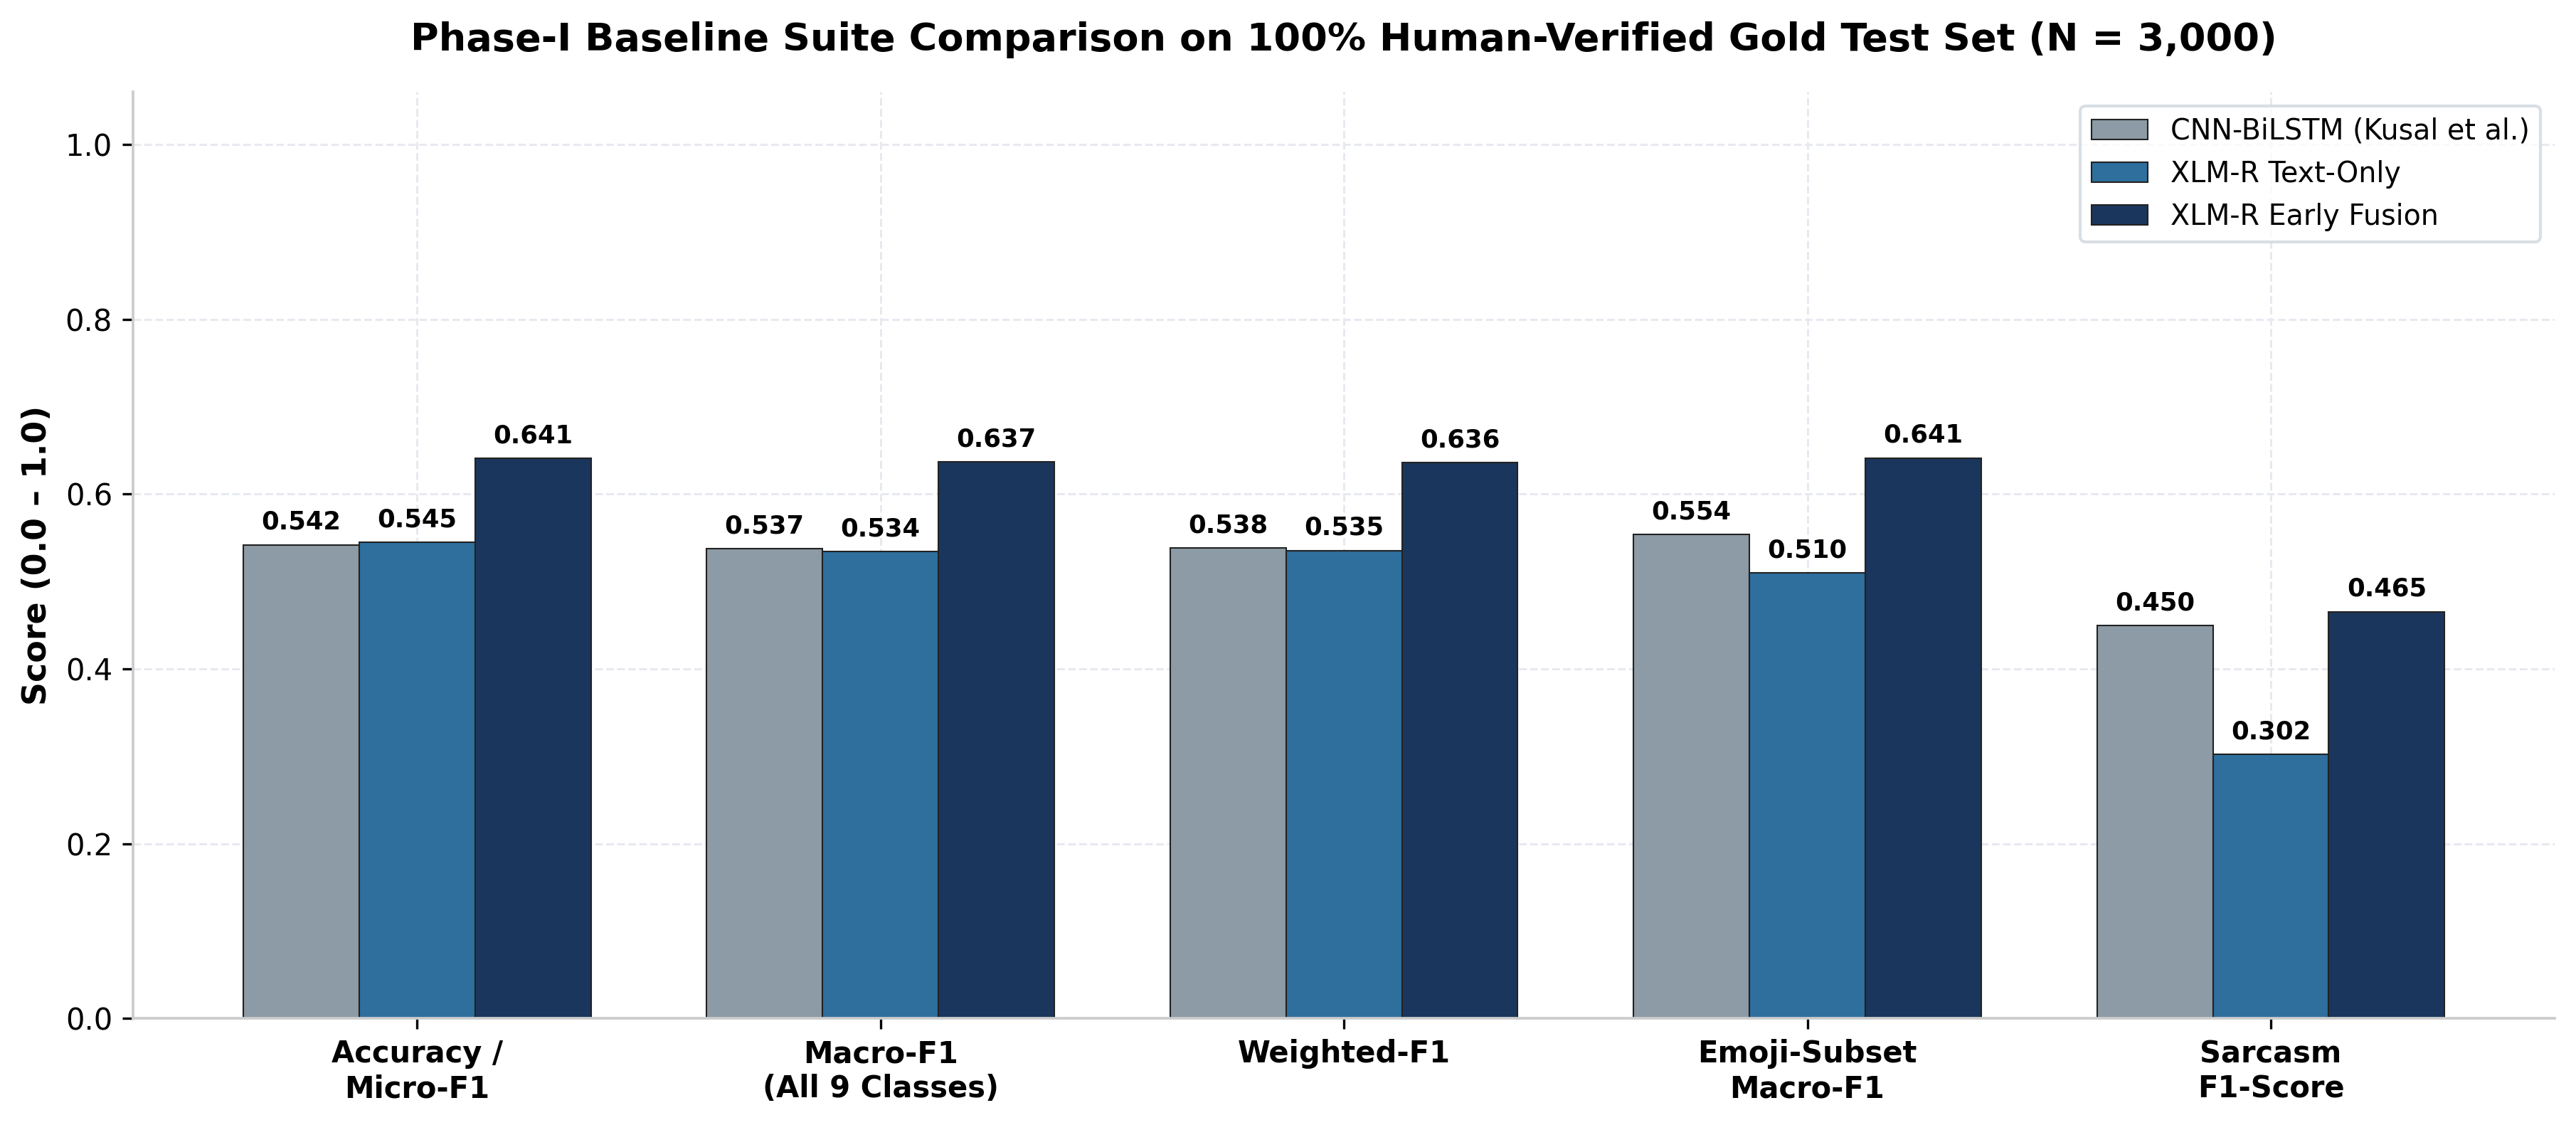

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/06_baseline_3model_comparison.png


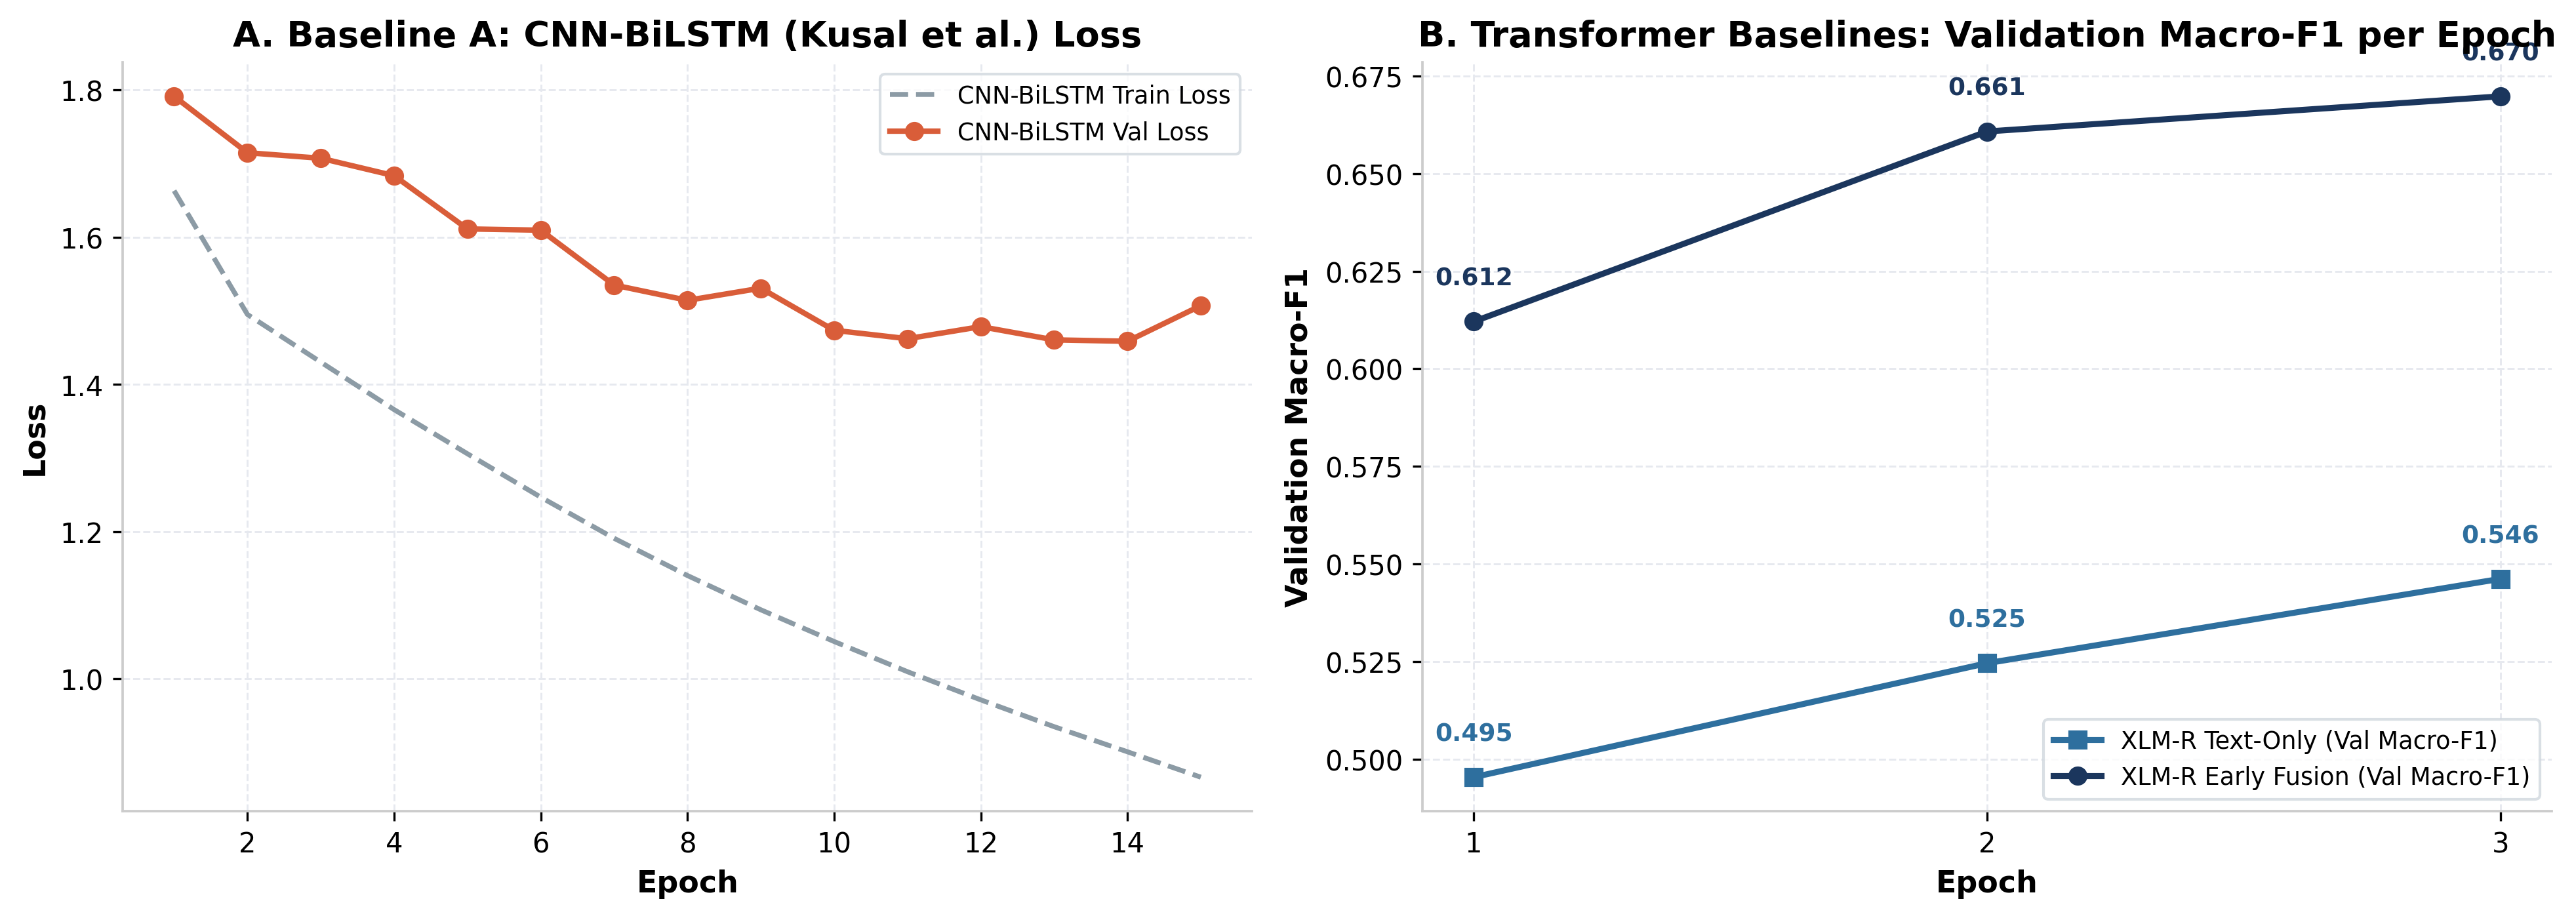

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/07_training_validation_curves.png


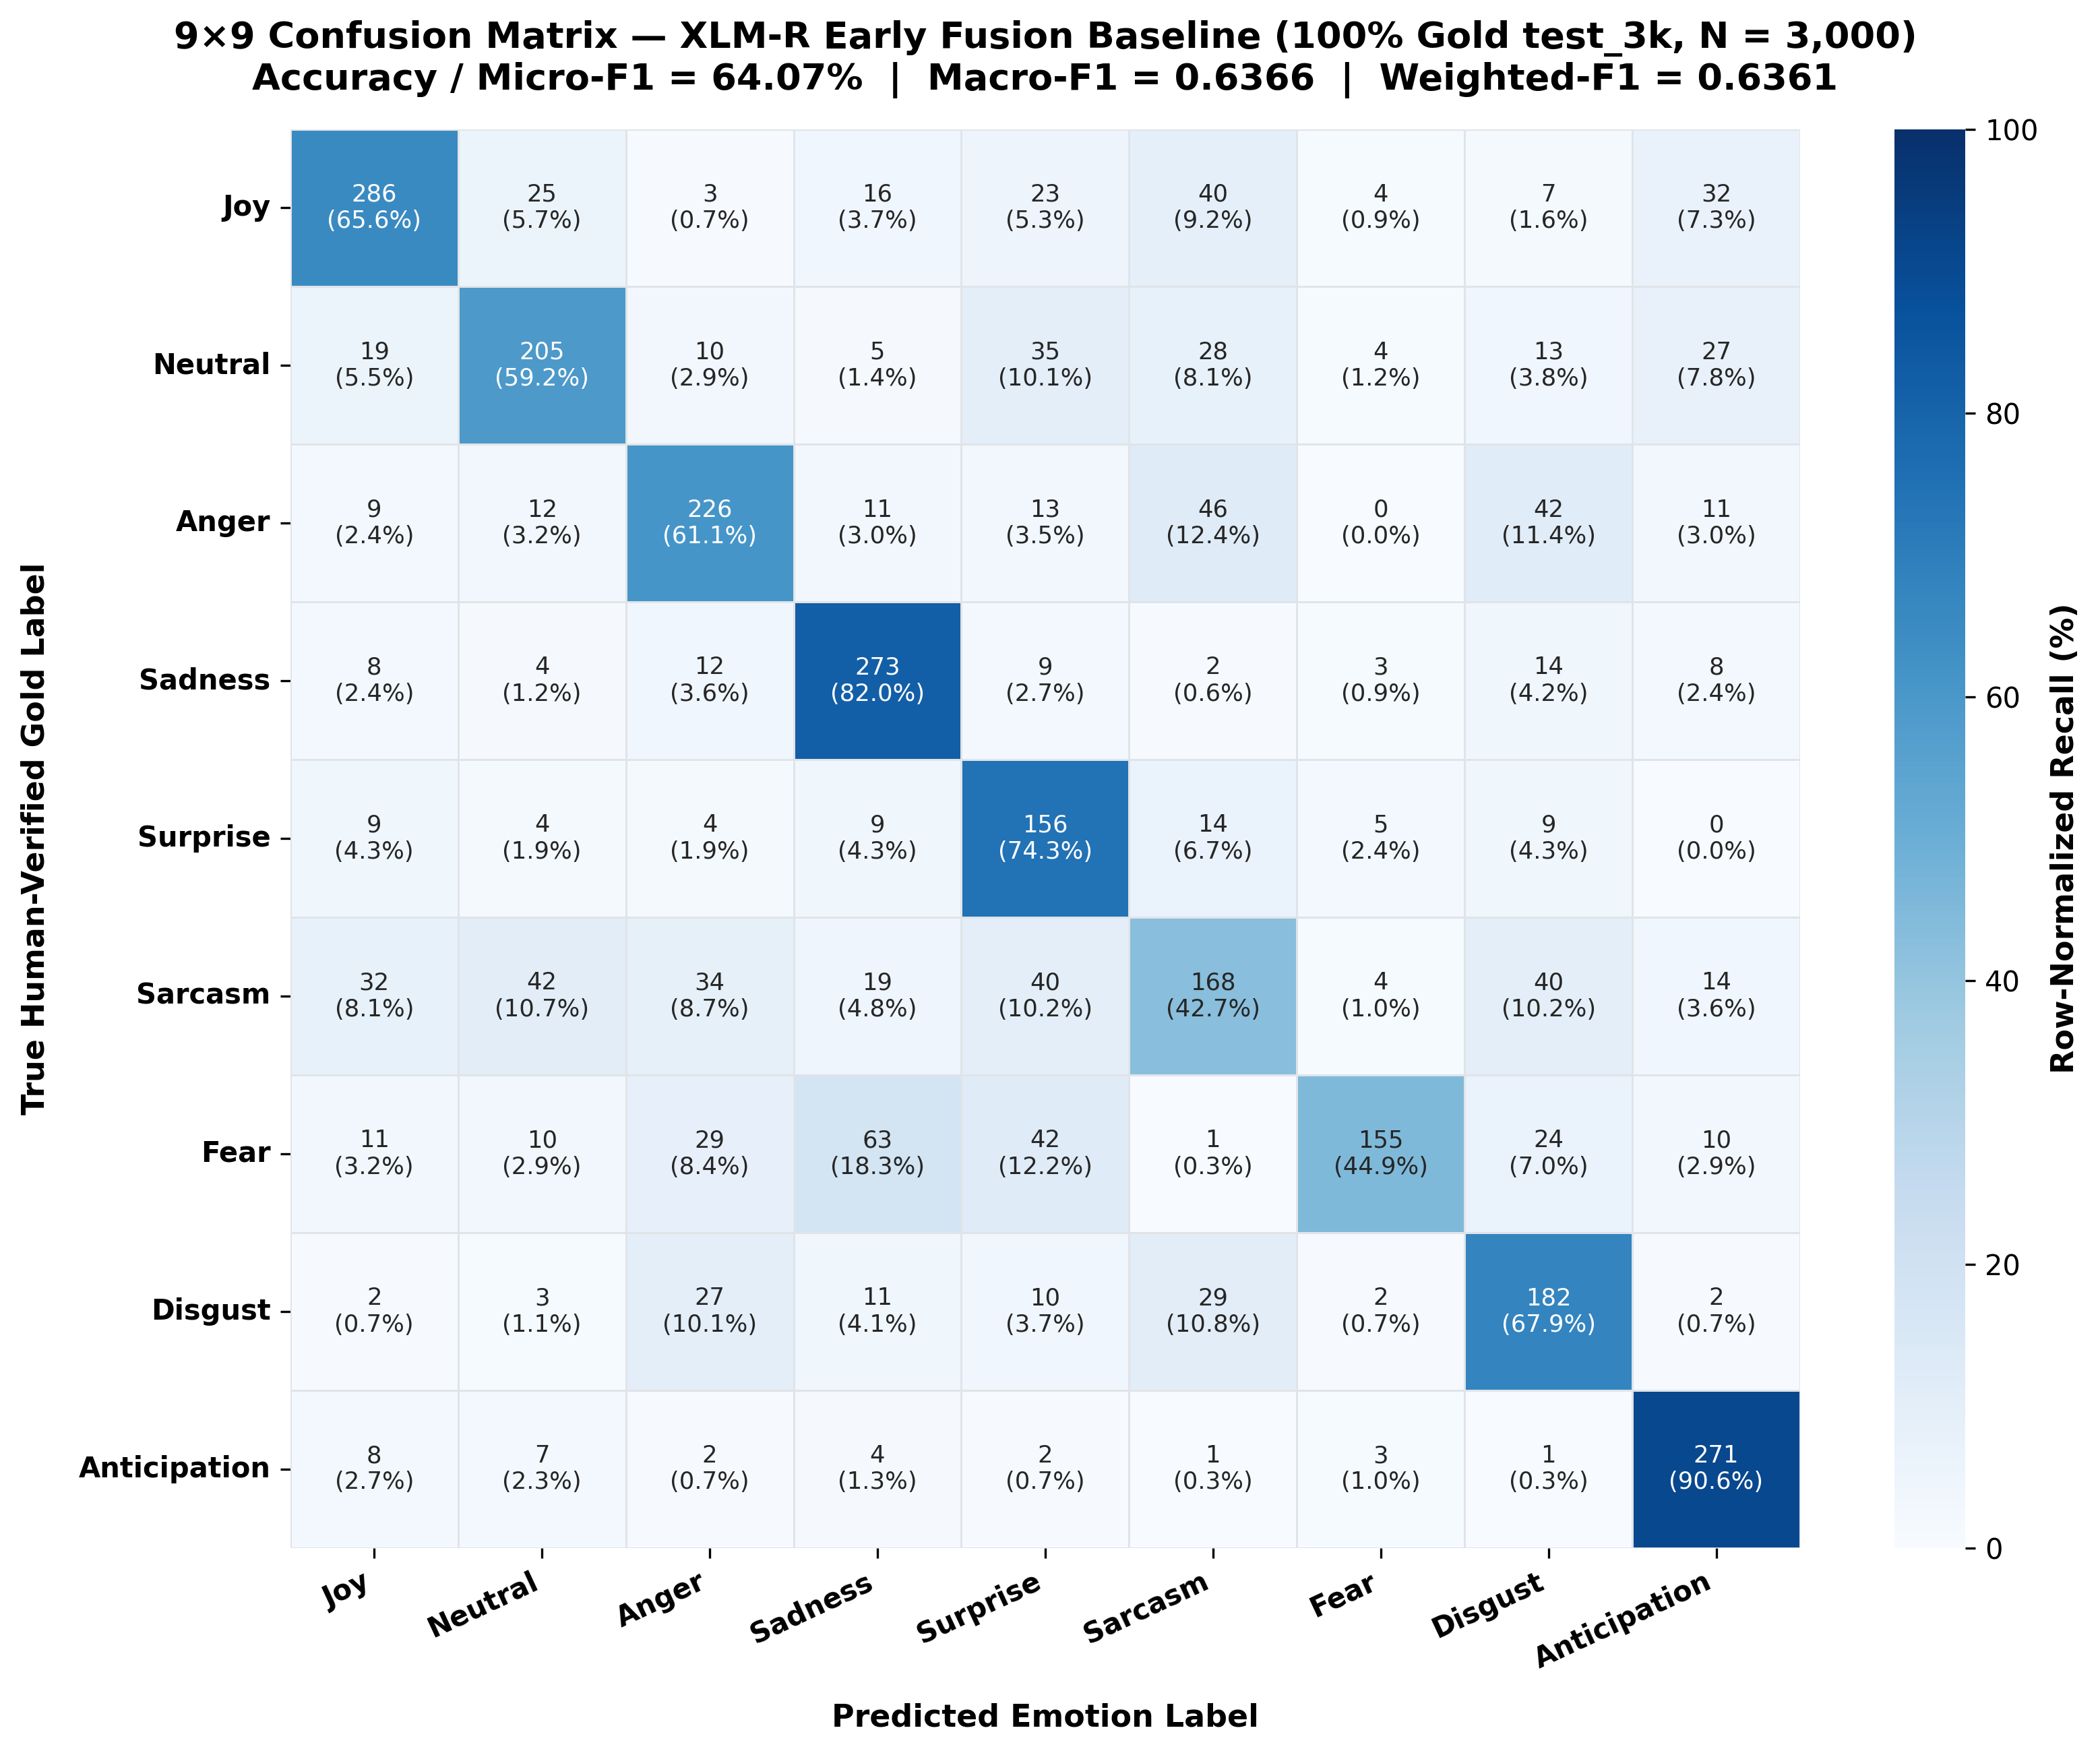

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/08_test_3k_confusion_matrix_9x9.png


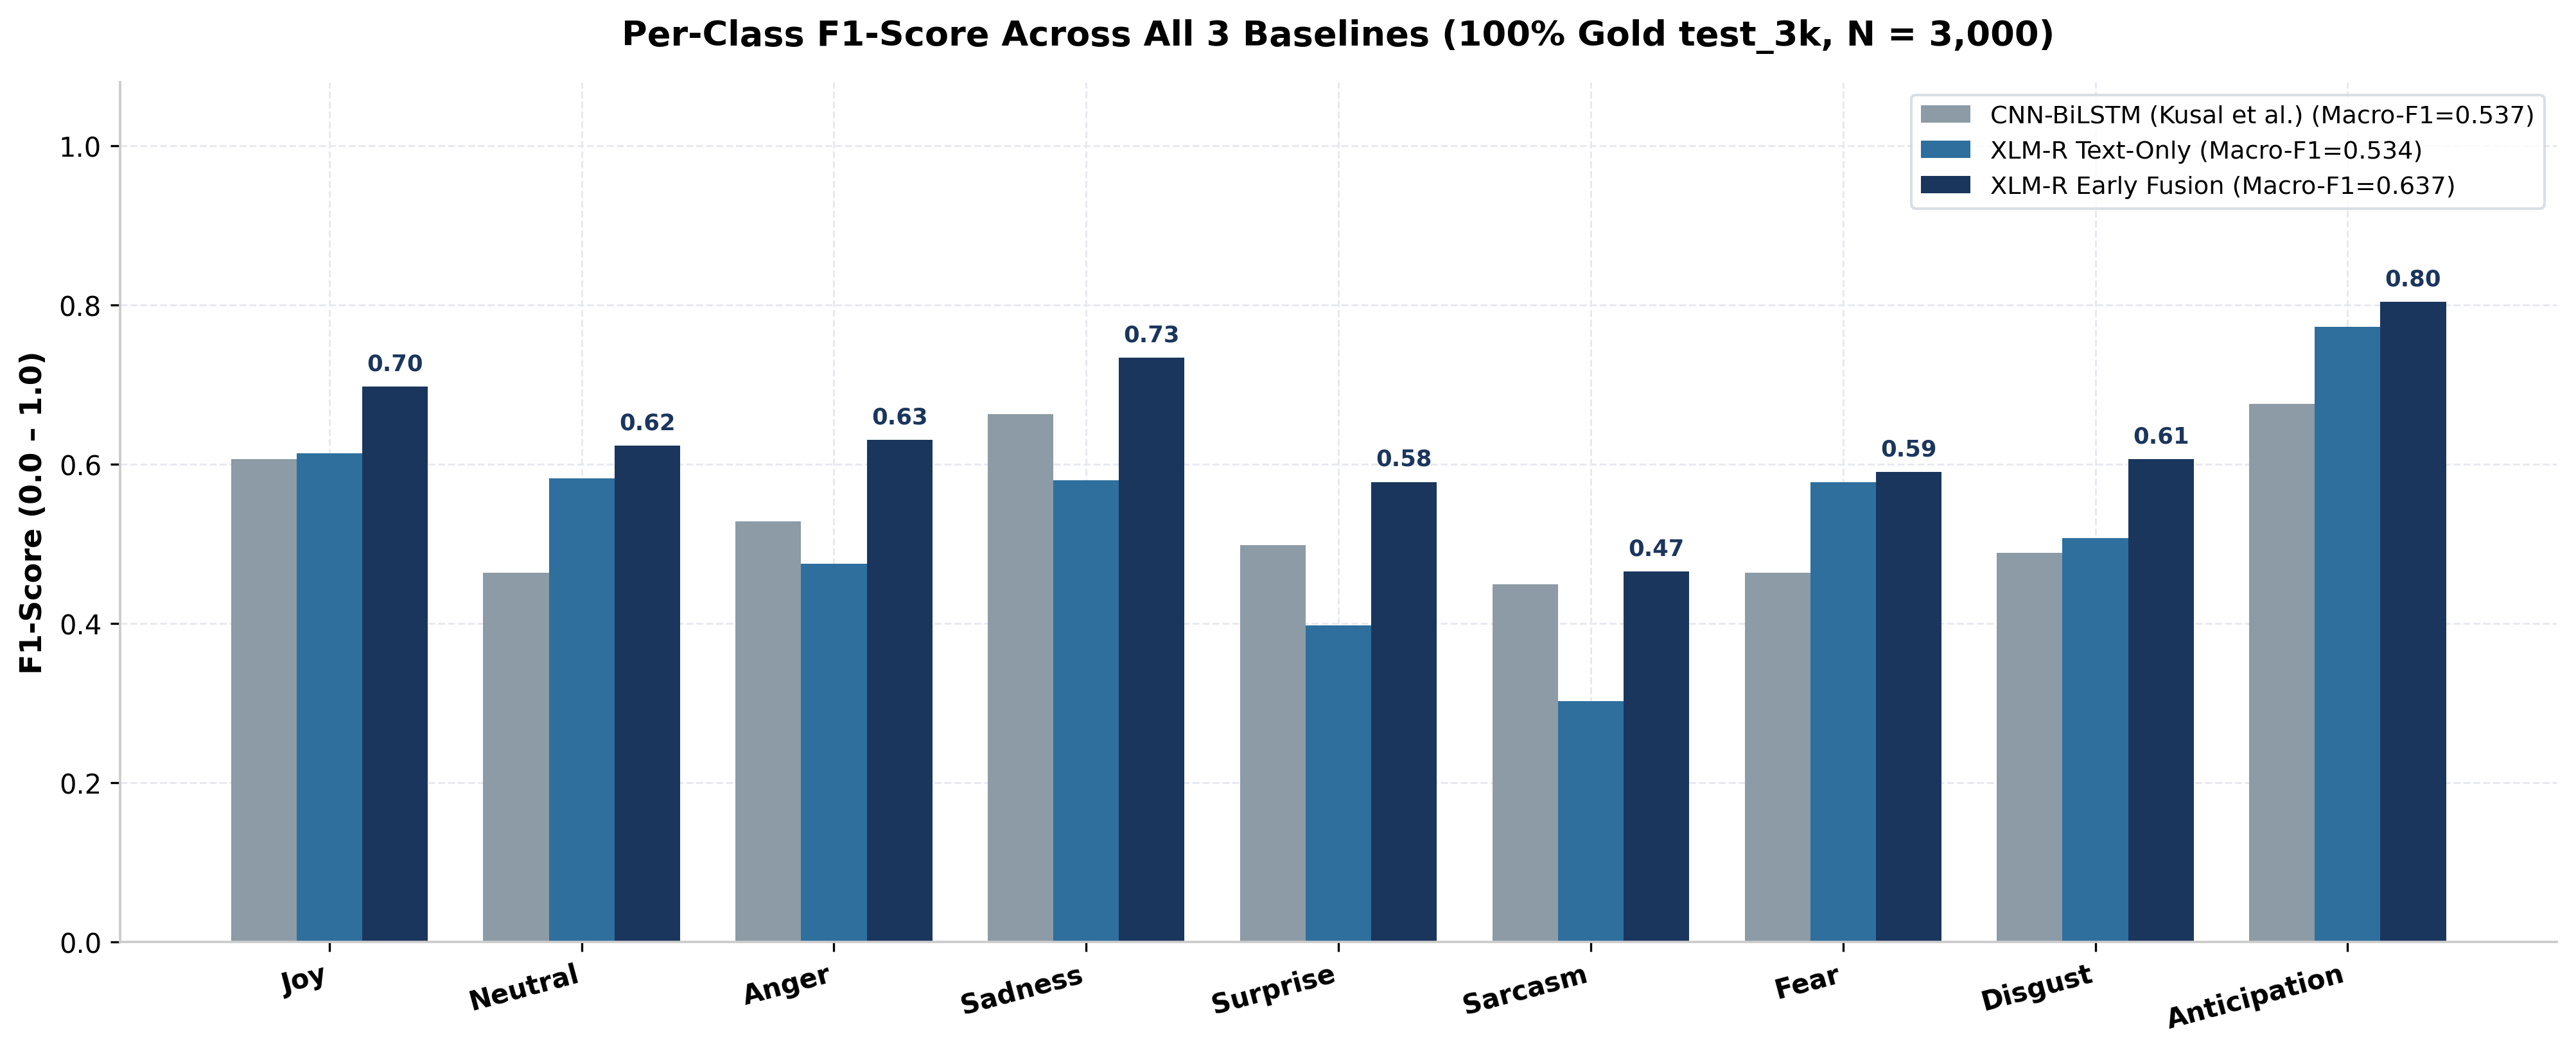

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/09_per_class_f1_comparison.png


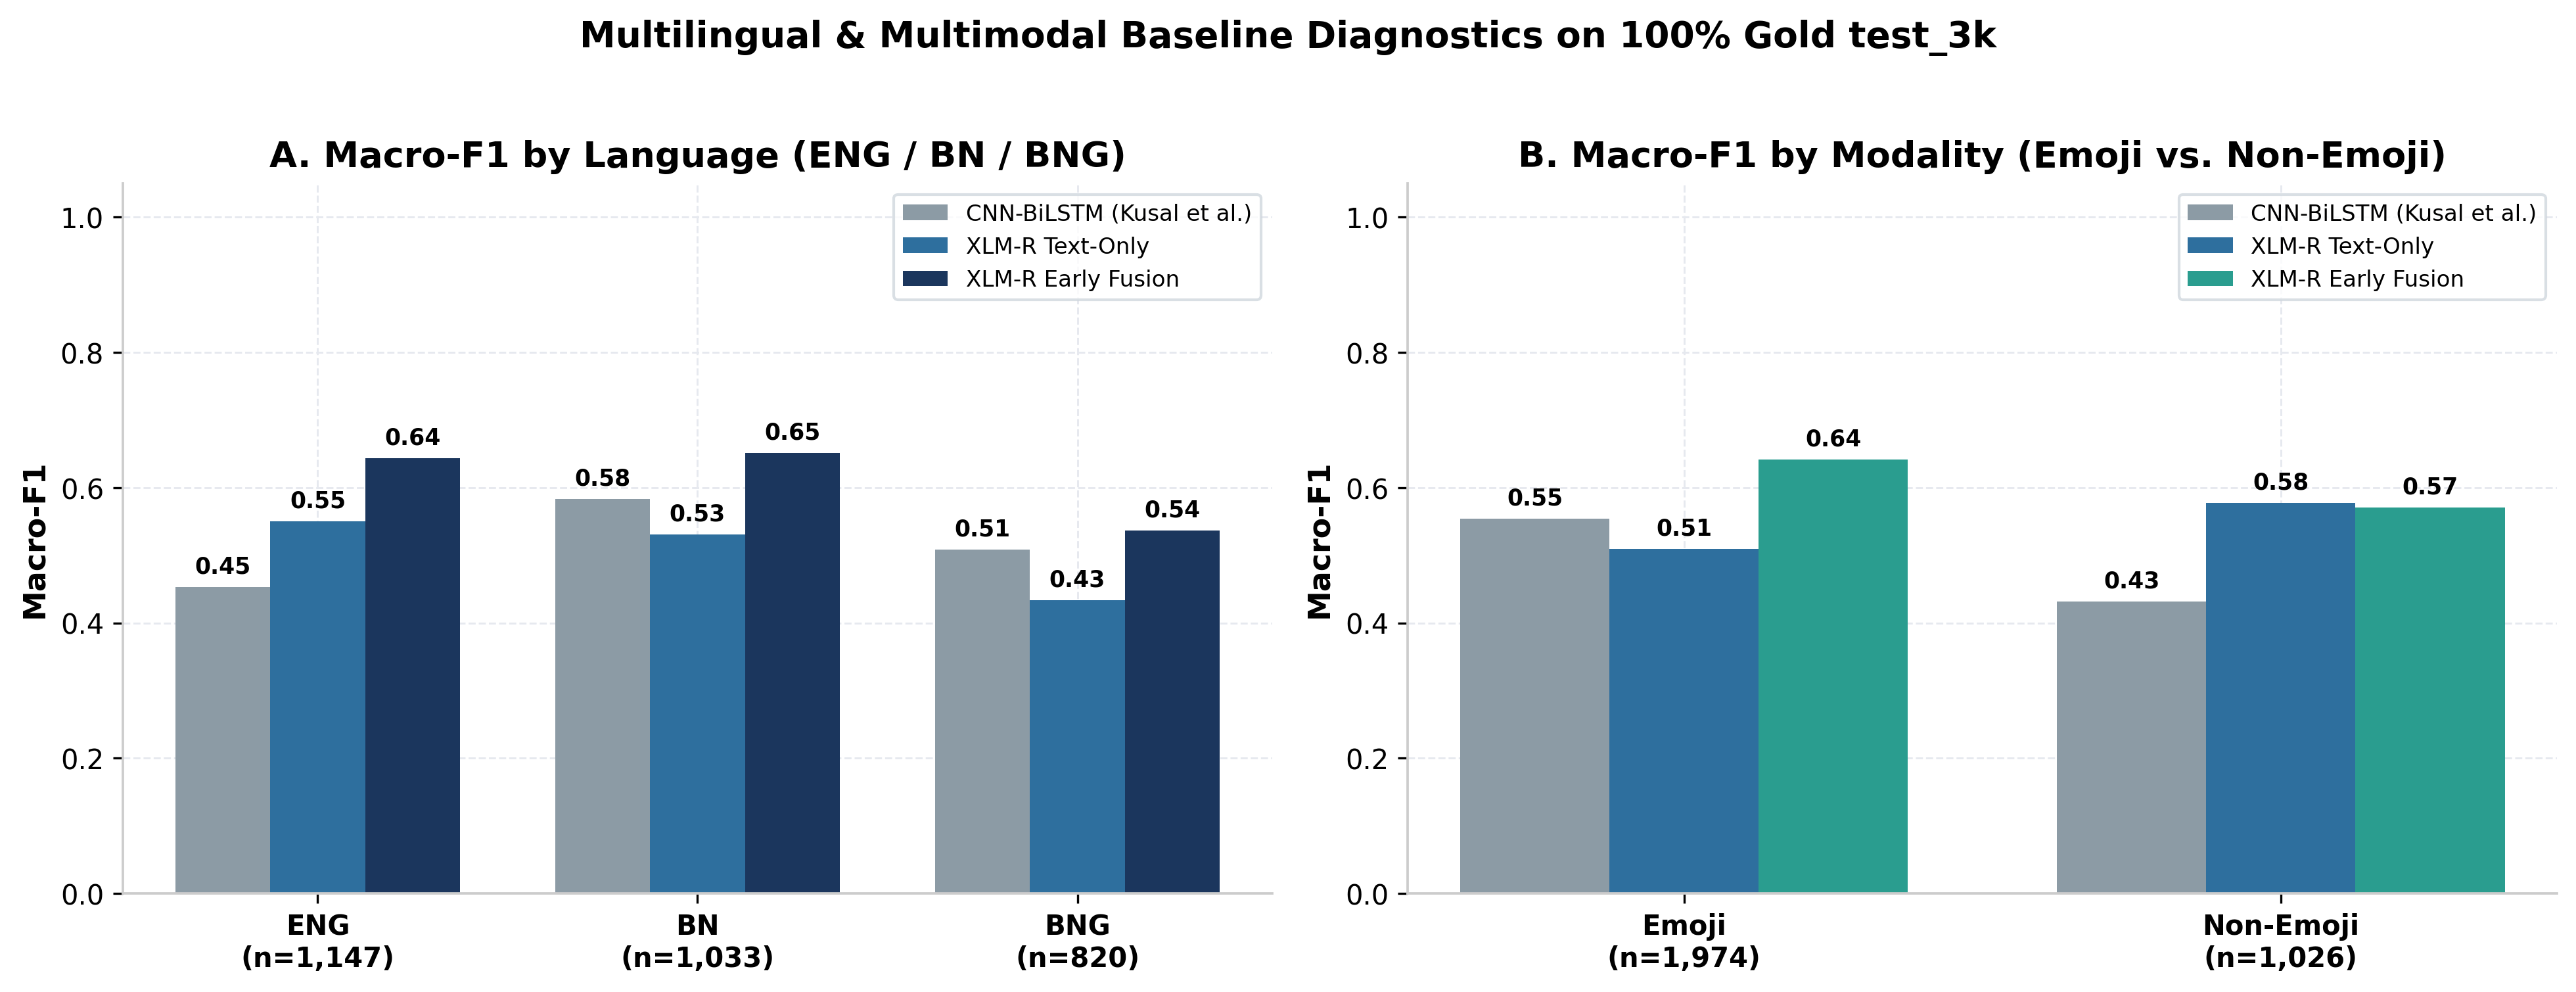

  [SAVED] /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/10_performance_by_language_and_modality.png

=== ALL DAY 4 v2 DELIVERABLES SAVED TO GOOGLE DRIVE ===
  EDA Charts (01-05)     : /content/drive/MyDrive/AffectFusion_Day4/01_eda_charts
  Eval Charts (06-10)    : /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts
  Master Comparison CSV  : /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/baseline_comparison_summary.csv
  Significance Tests JSON: /content/drive/MyDrive/AffectFusion_Day4/logs/stage5_statistical_significance_tests.json
  Error Analysis CSV     : /content/drive/MyDrive/AffectFusion_Day4/03_evaluation_and_charts/test_3k_error_analysis.csv (1,078 errors)

=== TOP 10 HIGH-CONFIDENCE EARLY-FUSION ERRORS (MOTIVATES PHASE-II CROSS-ATTENTION) ===


,row_id,language_tag,label,pred_xlmr_text,pred_xlmr_fusion,fusion_conf,text_stream,demoji_text
0,AFG_031692,BN,Joy,Anticipation,Anticipation,0.9742,"আপনাদের নতুন ভিডিও এর অপেক্ষায় ছিলাম, আপনাদের ভিডিও দেখা সেই স্বাদ","red heart, red heart"
1,AFT_004329,ENG,Joy,Anticipation,Anticipation,0.9737,Was waiting for this episode! Thanks,smiling face with smiling eyes
2,AFG_045012,BNG,Sarcasm,Sarcasm,Surprise,0.9726,Eta k emnitei k chine...,"astonished face, astonished face"
3,AFG_054608,BNG,Sadness,Sadness,Surprise,0.9699,Ager moto ar nai moja Simul nei tao,face with open mouth
4,AFT_004360,BN,Joy,Anticipation,Anticipation,0.9694,"ভাইয়া আপনের ভিডিওর অপেক্ষায় ছিলাম কারণ আপনের মতো কেউ বুঝাইতে পারে না,ধন্যবাদ...",red heart
5,AFG_004494,ENG,Sarcasm,Anticipation,Anticipation,0.9690,"""Incel horror story"" oh boy I can't wait for Nik's autobiography",
6,AFT_004318,BNG,Joy,Anticipation,Anticipation,0.9684,Ei video er opekkhay cilam vai. Thanks,
7,AFG_023478,BN,Joy,Anticipation,Anticipation,0.9678,এইটাই অপেক্ষা করছিলাম দাদা হেব্বি করেছে বিগ বসকে রোস্ট করেছো,"red heart, red heart, red heart"
8,AFG_035192,BNG,Joy,Joy,Surprise,0.9659,Natok ta onk sondur hoice,face with open mouth
9,AFT_010818,BNG,Neutral,Neutral,Surprise,0.9658,Tmr number ta deo.amio to onei asi,face with open mouth


In [8]:
# ==============================================================================
# STAGE 5: UNIFIED 3-MODEL EVALUATION, PAIRED TESTS & 300-DPI DEFENSE CHARTS
# ==============================================================================
def compute_full_metrics(df_split: pd.DataFrame, res: dict, model_tag: str, split_tag: str) -> dict:
    y_true, y_pred = res["labels"], res["preds"]
    acc = float(accuracy_score(y_true, y_pred))
    p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    f1_mic = float(f1_score(y_true, y_pred, average="micro", zero_division=0))
    _, _, f1_wt, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    p_cls, r_cls, f1_cls, sup_cls = precision_recall_fscore_support(y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)

    per_class = {
        c: {"precision": round(float(p_cls[i]), 4), "recall": round(float(r_cls[i]), 4),
            "f1": round(float(f1_cls[i]), 4), "support": int(sup_cls[i])}
        for i, c in enumerate(CLASSES)
    }

    by_lang = {}
    for lg in ("ENG", "BN", "BNG"):
        m = (df_split["language_tag"].values == lg)
        if m.sum() > 0:
            by_lang[lg] = {
                "support": int(m.sum()),
                "accuracy": round(float(accuracy_score(y_true[m], y_pred[m])), 4),
                "macro_f1": round(float(f1_score(y_true[m], y_pred[m], average="macro", zero_division=0)), 4),
                "micro_f1": round(float(f1_score(y_true[m], y_pred[m], average="micro", zero_division=0)), 4),
                "weighted_f1": round(float(f1_score(y_true[m], y_pred[m], average="weighted", zero_division=0)), 4),
            }

    by_mod = {}
    for mv, mname in [(1, "Emoji"), (0, "Non-Emoji")]:
        m = (df_split["has_emoji"].values == mv)
        if m.sum() > 0:
            by_mod[mname] = {
                "support": int(m.sum()),
                "accuracy": round(float(accuracy_score(y_true[m], y_pred[m])), 4),
                "macro_f1": round(float(f1_score(y_true[m], y_pred[m], average="macro", zero_division=0)), 4),
                "weighted_f1": round(float(f1_score(y_true[m], y_pred[m], average="weighted", zero_division=0)), 4),
            }

    return {
        "model": model_tag, "split": split_tag, "rows": int(len(y_true)),
        "loss": round(float(res["loss"]), 4),
        "accuracy": round(acc, 4),
        "macro_precision": round(float(p_mac), 4),
        "macro_recall": round(float(r_mac), 4),
        "macro_f1": round(float(f1_mac), 4),
        "micro_f1": round(f1_mic, 4),
        "weighted_f1": round(float(f1_wt), 4),
        "per_class": per_class,
        "by_language": by_lang,
        "by_modality": by_mod,
    }

def paired_significance_suite(y_true, pred_a, pred_b, name_a: str, name_b: str, mask=None, n_boot: int = 1000) -> dict:
    """
    Compare Model B vs. Model A on the exact same test samples:
      1) Paired t-test on per-sample correctness (proposal Section 6)
      2) McNemar's continuity-corrected chi-square test
      3) 1,000-sample paired bootstrap 95% CI on Macro-F1 delta (B - A)
    """
    if mask is not None:
        yt, pa, pb = y_true[mask], pred_a[mask], pred_b[mask]
    else:
        yt, pa, pb = y_true, pred_a, pred_b

    corr_a = (pa == yt).astype(float)
    corr_b = (pb == yt).astype(float)
    acc_diff = float(corr_b.mean() - corr_a.mean())

    # 1. Paired t-test (two-sided)
    t_stat, p_ttest = stats.ttest_rel(corr_b, corr_a)
    t_stat  = 0.0 if np.isnan(t_stat)  else float(t_stat)
    p_ttest = 1.0 if np.isnan(p_ttest) else float(p_ttest)

    # 2. McNemar's test (n01: A wrong & B right; n10: A right & B wrong)
    n01 = int(((corr_a == 0) & (corr_b == 1)).sum())
    n10 = int(((corr_a == 1) & (corr_b == 0)).sum())
    if (n01 + n10) > 0:
        chi2_mc = ((abs(n01 - n10) - 1.0) ** 2) / (n01 + n10)
        p_mcnemar = float(stats.chi2.sf(chi2_mc, df=1))
    else:
        chi2_mc, p_mcnemar = 0.0, 1.0

    # 3. Paired Bootstrap on Macro-F1 difference (B - A)
    rng = np.random.RandomState(CONFIG["RANDOM_SEED"])
    n = len(yt)
    deltas = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, size=n)
        f1_a = f1_score(yt[idx], pa[idx], average="macro", zero_division=0)
        f1_b = f1_score(yt[idx], pb[idx], average="macro", zero_division=0)
        deltas.append(f1_b - f1_a)
    f1_a_obs = float(f1_score(yt, pa, average="macro", zero_division=0))
    f1_b_obs = float(f1_score(yt, pb, average="macro", zero_division=0))
    ci_lo, ci_hi = np.percentile(deltas, [2.5, 97.5])

    return {
        "comparison": f"{name_b} vs. {name_a}",
        "n_samples": int(n),
        "acc_A": round(float(corr_a.mean()), 4),
        "acc_B": round(float(corr_b.mean()), 4),
        "acc_delta_B_minus_A": round(acc_diff, 4),
        "paired_t_stat": round(t_stat, 4),
        "paired_t_pvalue": round(p_ttest, 6),
        "significant_at_0_05_ttest": bool(p_ttest < 0.05),
        "mcnemar_B_right_A_wrong": n01,
        "mcnemar_A_right_B_wrong": n10,
        "mcnemar_chi2": round(float(chi2_mc), 4),
        "mcnemar_pvalue": round(p_mcnemar, 6),
        "macro_f1_A": round(f1_a_obs, 4),
        "macro_f1_B": round(f1_b_obs, 4),
        "macro_f1_delta": round(f1_b_obs - f1_a_obs, 4),
        "macro_f1_delta_95ci": [round(float(ci_lo), 4), round(float(ci_hi), 4)],
    }

def run_stage5_unified_evaluation():
    criterion = nn.CrossEntropyLoss()
    all_metrics = {"val_3k": {}, "test_3k_gold": {}}
    test_raw_results = {}

    # --------------------------------------------------------------------------
    # 1. Evaluate Baseline A: CNN-BiLSTM Early Fusion (Kusal et al., 2025)
    # --------------------------------------------------------------------------
    print(">>> Evaluating Baseline A: CNN-BiLSTM Early Fusion (Kusal et al., 2025)...")
    with open(os.path.join(DIRS["ckpt_cnn_bilstm"], "vocabs.json"), "r", encoding="utf-8") as f:
        voc = json.load(f)
    ckpt_cnn = torch.load(os.path.join(DIRS["ckpt_cnn_bilstm"], "best_cnn_bilstm.pt"), map_location=device, weights_only=False)
    m_cnn = KusalCNNBiLSTMEarlyFusion(ckpt_cnn["text_vocab_size"], ckpt_cnn["emoji_vocab_size"], NUM_CLASSES).to(device)
    m_cnn.load_state_dict(ckpt_cnn["model_state_dict"])

    va_cnn_ld = DataLoader(KusalCNNBiLSTMDataset(df_val_m,  tokenizer, voc["tok2idx"], voc["emo2idx"], CONFIG["MAX_LENGTH"]), batch_size=128, shuffle=False, collate_fn=kusal_collate_fn)
    te_cnn_ld = DataLoader(KusalCNNBiLSTMDataset(df_test_m, tokenizer, voc["tok2idx"], voc["emo2idx"], CONFIG["MAX_LENGTH"]), batch_size=128, shuffle=False, collate_fn=kusal_collate_fn)

    res_va_cnn = evaluate_cnn_bilstm(m_cnn, va_cnn_ld, criterion)
    res_te_cnn = evaluate_cnn_bilstm(m_cnn, te_cnn_ld, criterion)
    all_metrics["val_3k"]["CNN-BiLSTM (Kusal et al.)"]       = compute_full_metrics(df_val_m,  res_va_cnn, "CNN-BiLSTM (Kusal et al.)", "val_3k")
    all_metrics["test_3k_gold"]["CNN-BiLSTM (Kusal et al.)"] = compute_full_metrics(df_test_m, res_te_cnn, "CNN-BiLSTM (Kusal et al.)", "test_3k_gold")
    test_raw_results["CNN-BiLSTM (Kusal et al.)"] = res_te_cnn

    df_p_cnn = df_test_m.copy()
    df_p_cnn["pred_label"] = [ID2LABEL[int(i)] for i in res_te_cnn["preds"]]
    df_p_cnn["pred_conf"]  = np.round(np.max(res_te_cnn["probs"], axis=-1), 4)
    df_p_cnn["is_correct"] = (df_p_cnn["label_id"].values == res_te_cnn["preds"]).astype(int)
    df_p_cnn.to_csv(os.path.join(DIRS["eval_results"], "test_3k_pred_cnn_bilstm.csv"), index=False, encoding="utf-8-sig")

    del m_cnn, ckpt_cnn, va_cnn_ld, te_cnn_ld
    torch.cuda.empty_cache(); gc.collect()

    # --------------------------------------------------------------------------
    # 2. Evaluate Baseline B (XLM-R Text-Only) & Baseline C (XLM-R Early Fusion)
    # --------------------------------------------------------------------------
    xlmr_specs = [
        ("XLM-R Text-Only",    False, DIRS["ckpt_xlmr_text"],   "test_3k_pred_xlmr_text_only.csv"),
        ("XLM-R Early Fusion", True,  DIRS["ckpt_xlmr_fusion"], "test_3k_pred_xlmr_early_fusion.csv"),
    ]
    for m_name, use_dem, ckpt_dir, pred_fname in xlmr_specs:
        print(f">>> Evaluating {m_name} from {ckpt_dir}...")
        m_xlmr = AutoModelForSequenceClassification.from_pretrained(ckpt_dir).to(device)
        va_ld  = DataLoader(XLMRDataset(df_val_m,  tokenizer, CONFIG["MAX_LENGTH"], use_demoji=use_dem),
                            batch_size=CONFIG["XLMR_EVAL_BATCH_SIZE"], shuffle=False, num_workers=CONFIG["NUM_WORKERS"], pin_memory=True, collate_fn=xlmr_collator)
        te_ld  = DataLoader(XLMRDataset(df_test_m, tokenizer, CONFIG["MAX_LENGTH"], use_demoji=use_dem),
                            batch_size=CONFIG["XLMR_EVAL_BATCH_SIZE"], shuffle=False, num_workers=CONFIG["NUM_WORKERS"], pin_memory=True, collate_fn=xlmr_collator)

        res_va = evaluate_xlmr_loader(m_xlmr, va_ld, criterion, use_fp16=CONFIG["USE_FP16"])
        res_te = evaluate_xlmr_loader(m_xlmr, te_ld, criterion, use_fp16=CONFIG["USE_FP16"])
        all_metrics["val_3k"][m_name]       = compute_full_metrics(df_val_m,  res_va, m_name, "val_3k")
        all_metrics["test_3k_gold"][m_name] = compute_full_metrics(df_test_m, res_te, m_name, "test_3k_gold")
        test_raw_results[m_name] = res_te

        df_p = df_test_m.copy()
        df_p["pred_label_id"] = res_te["preds"]
        df_p["pred_label"]    = [ID2LABEL[int(i)] for i in res_te["preds"]]
        df_p["pred_conf"]     = np.round(np.max(res_te["probs"], axis=-1), 4)
        df_p["is_correct"]    = (df_p["label_id"].values == res_te["preds"]).astype(int)
        df_p.to_csv(os.path.join(DIRS["eval_results"], pred_fname), index=False, encoding="utf-8-sig")

        del m_xlmr, va_ld, te_ld
        torch.cuda.empty_cache(); gc.collect()

    # --------------------------------------------------------------------------
    # 3. Build Master Comparison Table + Statistical Significance Suite
    # --------------------------------------------------------------------------
    model_order = ["CNN-BiLSTM (Kusal et al.)", "XLM-R Text-Only", "XLM-R Early Fusion"]
    comp_rows = []
    for m_name in model_order:
        mv = all_metrics["val_3k"][m_name]
        mt = all_metrics["test_3k_gold"][m_name]
        comp_rows.append({
            "Model": m_name,
            "Val_Acc": mv["accuracy"],
            "Val_Macro_F1": mv["macro_f1"],
            "Test_Acc_MicroF1": mt["accuracy"],
            "Test_Macro_F1": mt["macro_f1"],
            "Test_Weighted_F1": mt["weighted_f1"],
            "Test_ENG_F1": mt["by_language"]["ENG"]["macro_f1"],
            "Test_BN_F1": mt["by_language"]["BN"]["macro_f1"],
            "Test_BNG_F1": mt["by_language"]["BNG"]["macro_f1"],
            "Test_Emoji_F1": mt["by_modality"]["Emoji"]["macro_f1"],
            "Test_NonEmoji_F1": mt["by_modality"]["Non-Emoji"]["macro_f1"],
            "Test_Sarcasm_F1": mt["per_class"]["Sarcasm"]["f1"],
        })
    df_comp = pd.DataFrame(comp_rows)
    df_comp.to_csv(CONFIG["COMPARE_TABLE_CSV"], index=False, encoding="utf-8-sig")

    y_te = df_test_m["label_id"].values
    p_cnn = test_raw_results["CNN-BiLSTM (Kusal et al.)"]["preds"]
    p_txt = test_raw_results["XLM-R Text-Only"]["preds"]
    p_fus = test_raw_results["XLM-R Early Fusion"]["preds"]
    emo_mask  = (df_test_m["has_emoji"].values == 1)
    sarc_mask = (y_te == LABEL2ID["Sarcasm"])

    sig_tests = {
        "xlmr_fusion_vs_xlmr_text_ALL_3000":   paired_significance_suite(y_te, p_txt, p_fus, "XLM-R Text-Only", "XLM-R Early Fusion"),
        "xlmr_fusion_vs_xlmr_text_EMOJI_ONLY": paired_significance_suite(y_te, p_txt, p_fus, "XLM-R Text-Only", "XLM-R Early Fusion", mask=emo_mask),
        "xlmr_fusion_vs_cnn_bilstm_ALL_3000":  paired_significance_suite(y_te, p_cnn, p_fus, "CNN-BiLSTM (Kusal)", "XLM-R Early Fusion"),
        "xlmr_text_vs_cnn_bilstm_ALL_3000":    paired_significance_suite(y_te, p_cnn, p_txt, "CNN-BiLSTM (Kusal)", "XLM-R Text-Only"),
    }
    with open(CONFIG["SIG_TESTS_JSON"], "w", encoding="utf-8") as f:
        json.dump(sig_tests, f, indent=2)

    with open(CONFIG["EVAL_ALL_JSON"], "w", encoding="utf-8") as f:
        json.dump({
            "evaluated_at": datetime.now(timezone.utc).isoformat(),
            "metrics": all_metrics,
            "statistical_significance": sig_tests,
        }, f, indent=2)

    # Export Error Analysis CSV highlighting cases where XLM-R Early Fusion fails (esp. Sarcasm & Emoji rows)
    df_err = df_test_m.copy()
    df_err["pred_cnn_bilstm"]    = [ID2LABEL[int(i)] for i in p_cnn]
    df_err["pred_xlmr_text"]     = [ID2LABEL[int(i)] for i in p_txt]
    df_err["pred_xlmr_fusion"]   = [ID2LABEL[int(i)] for i in p_fus]
    df_err["fusion_conf"]        = np.round(np.max(test_raw_results["XLM-R Early Fusion"]["probs"], axis=-1), 4)
    df_err = df_err[df_err["label_id"].values != p_fus].sort_values("fusion_conf", ascending=False).reset_index(drop=True)
    df_err.to_csv(CONFIG["TEST_ERRORS_CSV"], index=False, encoding="utf-8-sig")

    print("\n" + "=" * 112)
    print("PHASE-I 3-BASELINE MASTER COMPARISON TABLE (EVALUATED ON 100% HUMAN-VERIFIED GOLD test_3k, N = 3,000)")
    print("=" * 112)
    display(df_comp)

    print("\n--- Paired Statistical Significance Tests (Gold test_3k) ---")
    for k, st in sig_tests.items():
        print(
            f"  {st['comparison']:42s} (n={st['n_samples']:4d}) | "
            f"ΔAcc={st['acc_delta_B_minus_A']*100:+5.2f}% (t={st['paired_t_stat']:+.2f}, p={st['paired_t_pvalue']:.4g}) | "
            f"McNemar p={st['mcnemar_pvalue']:.4g} | ΔMacro-F1={st['macro_f1_delta']:+.4f} 95%CI={st['macro_f1_delta_95ci']}"
        )

    print("\n--- Detailed Per-Class Classification Report: Baseline C (XLM-R Early Fusion on Gold test_3k) ---")
    print(classification_report(y_te, p_fus, target_names=CLASSES, digits=4, zero_division=0))

    # ==========================================================================
    # CHART 6: 3-BASELINE MASTER COMPARISON BAR CHART (GOLD test_3k)
    # ==========================================================================
    fig, ax = plt.subplots(figsize=(12.2, 5.4), dpi=300)
    metric_keys = ["Test_Acc_MicroF1", "Test_Macro_F1", "Test_Weighted_F1", "Test_Emoji_F1", "Test_Sarcasm_F1"]
    metric_lbls = ["Accuracy /\nMicro-F1", "Macro-F1\n(All 9 Classes)", "Weighted-F1", "Emoji-Subset\nMacro-F1", "Sarcasm\nF1-Score"]
    mx = np.arange(len(metric_keys)); w = 0.25
    colors_m = ["#8C9BA5", "#2E6F9E", "#1B365D"]

    for i, (m_name, col) in enumerate(zip(model_order, colors_m)):
        vals = [df_comp.loc[df_comp["Model"] == m_name, k].values[0] for k in metric_keys]
        bars = ax.bar(mx + (i - 1) * w, vals, width=w, color=col, edgecolor="#222222", linewidth=0.5, label=m_name)
        for b in bars:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + 0.012, f"{h:.3f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

    ax.set_xticks(mx); ax.set_xticklabels(metric_lbls, fontweight="bold")
    ax.set_ylabel("Score (0.0 – 1.0)"); ax.set_ylim(0, 1.06)
    ax.set_title("Phase-I Baseline Suite Comparison on 100% Human-Verified Gold Test Set (N = 3,000)", pad=14)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(loc="upper right", frameon=True, fontsize=9.5)
    plt.tight_layout()
    p6 = os.path.join(DIRS["eval_results"], "06_baseline_3model_comparison.png")
    fig.savefig(p6, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p6}")

    # ==========================================================================
    # CHART 7: TRAINING & VALIDATION CURVES ACROSS ALL 3 BASELINES
    # ==========================================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8), dpi=300)
    if os.path.exists(CONFIG["HIST_CNN_JSON"]):
        with open(CONFIG["HIST_CNN_JSON"]) as f: hc = json.load(f)
        ec = [e["epoch"] for e in hc["epochs"]]
        ax1.plot(ec, [e["train_loss"] for e in hc["epochs"]], "--", color="#8C9BA5", linewidth=1.8, label="CNN-BiLSTM Train Loss")
        ax1.plot(ec, [e["val_loss"]   for e in hc["epochs"]], "-o", color="#D95D39", linewidth=2.0, label="CNN-BiLSTM Val Loss")
        ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("A. Baseline A: CNN-BiLSTM (Kusal et al.) Loss")
        ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False); ax1.legend(fontsize=8.8)

    for hj, lbl, col, mk in [
        (CONFIG["HIST_XLMR_TEXT_JSON"],   "XLM-R Text-Only (Val Macro-F1)",    "#2E6F9E", "s"),
        (CONFIG["HIST_XLMR_FUSION_JSON"], "XLM-R Early Fusion (Val Macro-F1)", "#1B365D", "o"),
    ]:
        if os.path.exists(hj):
            with open(hj) as f: hx = json.load(f)
            ex = [e["epoch"] for e in hx["epochs"]]
            vf = [e["val_macro_f1"] for e in hx["epochs"]]
            ax2.plot(ex, vf, marker=mk, linewidth=2.2, color=col, label=lbl)
            for x_e, y_f in zip(ex, vf):
                ax2.text(x_e, y_f + 0.008, f"{y_f:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold", color=col)
    ax2.set_xticks([1, 2, 3]); ax2.set_xlabel("Epoch"); ax2.set_ylabel("Validation Macro-F1")
    ax2.set_title("B. Transformer Baselines: Validation Macro-F1 per Epoch")
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False); ax2.legend(fontsize=8.8)
    plt.tight_layout()
    p7 = os.path.join(DIRS["eval_results"], "07_training_validation_curves.png")
    fig.savefig(p7, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p7}")

    # ==========================================================================
    # CHART 8: 9x9 CONFUSION MATRIX — BEST BASELINE (XLM-R EARLY FUSION) ON GOLD test_3k
    # ==========================================================================
    best_m = all_metrics["test_3k_gold"]["XLM-R Early Fusion"]
    cm = confusion_matrix(y_te, p_fus, labels=list(range(NUM_CLASSES)))
    cm_pct = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100.0
    annot = np.array([[f"{cm[i,j]}\n({cm_pct[i,j]:.1f}%)" for j in range(NUM_CLASSES)] for i in range(NUM_CLASSES)])

    fig, ax = plt.subplots(figsize=(11.0, 8.8), dpi=300)
    sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100,
                xticklabels=CLASSES, yticklabels=CLASSES, linewidths=0.6, linecolor="#E0E4E8",
                annot_kws={"size": 8.5}, cbar_kws={"label": "Row-Normalized Recall (%)"}, ax=ax)
    ax.set_xlabel("Predicted Emotion Label", fontweight="bold", labelpad=10)
    ax.set_ylabel("True Human-Verified Gold Label", fontweight="bold", labelpad=10)
    ax.set_title(
        f"9×9 Confusion Matrix — XLM-R Early Fusion Baseline (100% Gold test_3k, N = 3,000)\n"
        f"Accuracy / Micro-F1 = {best_m['accuracy']*100:.2f}%  |  Macro-F1 = {best_m['macro_f1']:.4f}  |  Weighted-F1 = {best_m['weighted_f1']:.4f}",
        pad=14
    )
    plt.xticks(rotation=25, ha="right", fontweight="bold"); plt.yticks(rotation=0, fontweight="bold")
    plt.tight_layout()
    p8 = os.path.join(DIRS["eval_results"], "08_test_3k_confusion_matrix_9x9.png")
    fig.savefig(p8, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p8}")

    # ==========================================================================
    # CHART 9: PER-CLASS F1 COMPARISON ACROSS ALL 3 BASELINES (GOLD test_3k)
    # ==========================================================================
    fig, ax = plt.subplots(figsize=(13.5, 5.6), dpi=300)
    cx = np.arange(NUM_CLASSES); w = 0.26
    for i, (m_name, col) in enumerate(zip(model_order, ["#8C9BA5", "#2E6F9E", "#1B365D"])):
        vals = [all_metrics["test_3k_gold"][m_name]["per_class"][c]["f1"] for c in CLASSES]
        bars = ax.bar(cx + (i - 1) * w, vals, width=w, color=col, label=f"{m_name} (Macro-F1={all_metrics['test_3k_gold'][m_name]['macro_f1']:.3f})")
        if i == 2:
            for b in bars:
                h = b.get_height()
                ax.text(b.get_x() + b.get_width()/2, h + 0.015, f"{h:.2f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#1B365D")

    ax.set_xticks(cx); ax.set_xticklabels(CLASSES, rotation=15, ha="right", fontweight="bold")
    ax.set_ylabel("F1-Score (0.0 – 1.0)"); ax.set_ylim(0, 1.08)
    ax.set_title("Per-Class F1-Score Across All 3 Baselines (100% Gold test_3k, N = 3,000)", pad=14)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.legend(loc="upper right", fontsize=9.2)
    plt.tight_layout()
    p9 = os.path.join(DIRS["eval_results"], "09_per_class_f1_comparison.png")
    fig.savefig(p9, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p9}")

    # ==========================================================================
    # CHART 10: LANGUAGE (ENG/BN/BNG) & MODALITY (EMOJI vs NON-EMOJI) DIAGNOSTIC
    # ==========================================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.9), dpi=300)
    langs = ["ENG", "BN", "BNG"]; lx = np.arange(len(langs)); w2 = 0.25
    for i, (m_name, col) in enumerate(zip(model_order, ["#8C9BA5", "#2E6F9E", "#1B365D"])):
        vals = [all_metrics["test_3k_gold"][m_name]["by_language"][l]["macro_f1"] for l in langs]
        bars = ax1.bar(lx + (i - 1) * w2, vals, width=w2, color=col, label=m_name)
        for b in bars:
            ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.014, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=8.3, fontweight="bold")
    ax1.set_xticks(lx); ax1.set_xticklabels([f"{l}\n(n={best_m['by_language'][l]['support']:,})" for l in langs], fontweight="bold")
    ax1.set_ylim(0, 1.05); ax1.set_ylabel("Macro-F1"); ax1.set_title("A. Macro-F1 by Language (ENG / BN / BNG)")
    ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False); ax1.legend(fontsize=8.2)

    mods = ["Emoji", "Non-Emoji"]; mx = np.arange(len(mods))
    for i, (m_name, col) in enumerate(zip(model_order, ["#8C9BA5", "#2E6F9E", "#2A9D8F"])):
        vals = [all_metrics["test_3k_gold"][m_name]["by_modality"][m]["macro_f1"] for m in mods]
        bars = ax2.bar(mx + (i - 1) * w2, vals, width=w2, color=col, label=m_name)
        for b in bars:
            ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.014, f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=8.3, fontweight="bold")
    ax2.set_xticks(mx); ax2.set_xticklabels([f"{m}\n(n={best_m['by_modality'][m]['support']:,})" for m in mods], fontweight="bold")
    ax2.set_ylim(0, 1.05); ax2.set_ylabel("Macro-F1"); ax2.set_title("B. Macro-F1 by Modality (Emoji vs. Non-Emoji)")
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False); ax2.legend(fontsize=8.2)

    plt.suptitle("Multilingual & Multimodal Baseline Diagnostics on 100% Gold test_3k", fontweight="bold", y=1.02)
    plt.tight_layout()
    p10 = os.path.join(DIRS["eval_results"], "10_performance_by_language_and_modality.png")
    fig.savefig(p10, dpi=300, bbox_inches="tight"); plt.show(); plt.close(fig)
    print(f"  [SAVED] {p10}")

    print("\n=== ALL DAY 4 v2 DELIVERABLES SAVED TO GOOGLE DRIVE ===")
    print("  EDA Charts (01-05)     :", DIRS["eda_charts"])
    print("  Eval Charts (06-10)    :", DIRS["eval_results"])
    print("  Master Comparison CSV  :", CONFIG["COMPARE_TABLE_CSV"])
    print("  Significance Tests JSON:", CONFIG["SIG_TESTS_JSON"])
    print("  Error Analysis CSV     :", CONFIG["TEST_ERRORS_CSV"], f"({len(df_err):,} errors)")

    print("\n=== TOP 10 HIGH-CONFIDENCE EARLY-FUSION ERRORS (MOTIVATES PHASE-II CROSS-ATTENTION) ===")
    pd.set_option("display.max_colwidth", 80)
    display(df_err[["row_id", "language_tag", "label", "pred_xlmr_text", "pred_xlmr_fusion", "fusion_conf", "text_stream", "demoji_text"]].head(10))

run_stage5_unified_evaluation()
